In [1]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor

import re


<h2>Read-in Data</h2>

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [ ]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_tx_operating = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_tx_nonoperating = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_tx = pd.concat([campd_tx_operating, campd_tx_nonoperating])
del campd_tx_nonoperating
del campd_tx_operating
gc.collect()

# create full datetime column (date + hour)
campd_tx["datetime"] = pd.to_datetime(campd_tx["Date"].astype(str) + ' ' + campd_tx["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_tx.to_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Full.csv", index=False)

In [ ]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_tx["Date"] = pd.to_datetime(campd_tx["Date"])
campd_tx["datetime"] = pd.to_datetime(campd_tx["datetime"])

<h2>Preprocessing Methods</h2>

In [3]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # group by
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [4]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # create a df from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_tx, tx_control_cols = preprocess_nox_controls(campd_tx)
# tx_control_cols

In [5]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_tx, tx_code_cols = preprocess_program_codes(campd_tx)
# tx_code_cols

In [2]:
# adjust the immense number of changed unit types that are indicated by e. g. "(Started Dec 12, 2022)"
def parse_unit_type(unit_str, ref_date):

    parts = re.split(r',\s*(?![^()]*\))', unit_str) # split only on commas outside parentheses
    active_units = []

    for part in parts:
        match = re.match(r"^(.*?)\s*\(\s*(Started|Ended)\s+([A-Za-z]+ \d{1,2}, \d{4})\s*\)$", part.strip())
        if match:
            unit, action, date_str = match.groups()
            try:
                event_date = pd.to_datetime(date_str)
            except Exception:
                continue
            if action == "Started" and event_date <= ref_date:
                active_units.append(unit.strip())
            elif action == "Ended" and event_date > ref_date:
                active_units.append(unit.strip())
        else:
            active_units.append(part.strip())

    return ", ".join(active_units) if active_units else "Nothing"

<h2>Regression Models</h2>

<h3>Linear Regression</h3>

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners', 'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', num_pipeline, num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


In [ ]:
navals = X_train.isna().sum()
print(navals[navals>0])
navals = X_test.isna().sum()
print(navals[navals>0])

In [27]:
X_train = X_train.dropna()  
y_train = y_train[X_train.index] 
X_test = X_test.dropna()  
y_test = y_test[X_test.index] 

In [39]:
X_train = X_train.drop(columns=[
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ])
X_test = X_test.drop(columns=[
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ])

In [42]:
X_sampled, y_sampled = (
    X_train.sample(frac=0.5, random_state=42),
    y_train.loc[X_train.sample(frac=0.5, random_state=42).index]
)

In [49]:
y_pred

array([533.21875 ,   0.      ,   1.34375 , ..., 116.296875,   5.171875,
         5.171875])

In [57]:
X_test["num__Heat Input (mmBtu)"].describe()

count   1700434.000000
mean         -0.033544
std           0.893181
min          -1.056961
25%          -0.584028
50%          -0.037105
75%           0.182811
max           5.934112
Name: num__Heat Input (mmBtu), dtype: float64

In [64]:

pd.set_option('display.max_columns', None)


display(X_test.loc[[9582014, 9519735]])

,cat__Month_1.0,cat__Month_2.0,cat__Month_3.0,cat__Month_4.0,cat__Month_5.0,cat__Month_6.0,cat__Month_7.0,cat__Month_8.0,cat__Month_9.0,cat__Month_10.0,cat__Month_11.0,cat__Month_12.0,cat__Hour_0.0,cat__Hour_1.0,cat__Hour_2.0,cat__Hour_3.0,cat__Hour_4.0,cat__Hour_5.0,cat__Hour_6.0,cat__Hour_7.0,cat__Hour_8.0,cat__Hour_9.0,cat__Hour_10.0,cat__Hour_11.0,cat__Hour_12.0,cat__Hour_13.0,cat__Hour_14.0,cat__Hour_15.0,cat__Hour_16.0,cat__Hour_17.0,cat__Hour_18.0,cat__Hour_19.0,cat__Hour_20.0,cat__Hour_21.0,cat__Hour_22.0,cat__Hour_23.0,cat__Day_1.0,cat__Day_2.0,cat__Day_3.0,cat__Day_4.0,cat__Day_5.0,cat__Day_6.0,cat__Day_7.0,cat__Day_8.0,cat__Day_9.0,cat__Day_10.0,cat__Day_11.0,cat__Day_12.0,cat__Day_13.0,cat__Day_14.0,cat__Day_15.0,cat__Day_16.0,cat__Day_17.0,cat__Day_18.0,cat__Day_19.0,cat__Day_20.0,cat__Day_21.0,cat__Day_22.0,cat__Day_23.0,cat__Day_24.0,cat__Day_25.0,cat__Day_26.0,cat__Day_27.0,cat__Day_28.0,cat__Day_29.0,cat__Day_30.0,cat__Day_31.0,cat__Source Category_Cogeneration,cat__Source Category_Electric Utility,cat__Source Category_Missing,cat__NOx Phase_Early Election,cat__NOx Phase_Nothing,cat__Unit Type_Bubbling fluidized bed boiler,cat__Unit Type_Circulating fluidized bed boiler,cat__Unit Type_Combined cycle,cat__Unit Type_Combustion turbine,cat__Unit Type_Dry bottom wall-fired boiler,cat__Unit Type_Nothing,cat__Unit Type_Tangentially-fired,cat__Primary Fuel Type_Coal,cat__Primary Fuel Type_Natural Gas,cat__Primary Fuel Type_Other Gas,cat__Primary Fuel Type_Pipeline Natural Gas,cat__Primary Fuel Type_Wood,cat__Secondary Fuel Type_Diesel Oil,"cat__Secondary Fuel Type_Diesel Oil, Other Oil","cat__Secondary Fuel Type_Diesel Oil, Other Solid Fuel","cat__Secondary Fuel Type_Diesel Oil, Residual Oil",cat__Secondary Fuel Type_Nothing,cat__Secondary Fuel Type_Other Gas,"cat__Secondary Fuel Type_Other Gas, Process Gas",cat__Secondary Fuel Type_Other Oil,cat__Secondary Fuel Type_Pipeline Natural Gas,cat__Secondary Fuel Type_Process Gas,cat__Secondary Fuel Type_Residual Oil,num__Gross Load (MW),num__Heat Input (mmBtu),num__Latitude,num__Longitude,num__Nameplate Capacity (MWe),num__hourly_capacity_factor,num__hourly_ramping_factor,num__Summer Capacity (MW),num__Winter Capacity (MW),num__Minimum Load (MW),num__Year,num__Temperature (F),encoded__Ammonia Injection,encoded__Combustion Modification/Fuel Reburning,encoded__Dry Low NOx Burners,"encoded__Dry Low NOx Burners (Began Aug 03, 2022)","encoded__Dry Low NOx Burners (Began Jul 01, 2024)",encoded__Low NOx Burner Technology (Dry Bottom only),encoded__Low NOx Burner Technology w/ Closed-coupled OFA,encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA,encoded__Low NOx Burner Technology w/ Overfire Air,encoded__Low NOx Burner Technology w/ Separated OFA,encoded__Nothing,encoded__Other,encoded__Overfire Air,encoded__Selective Catalytic Reduction,encoded__Selective Non-catalytic Reduction,encoded__Steam Injection,"encoded__Steam Injection (Retired Aug 02, 2022)","encoded__Steam Injection (Retired Jun 30, 2024)",encoded__Water Injection,encoded__ARP,encoded__CSOSG2,encoded__MATS,encoded__Missing,encoded__TXSO2
9582014,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.754823,-0.5245

In [53]:
df = pd.DataFrame({"y_test": y_test, "y_pred": y_pred, "difference": np.abs(y_test - y_pred)})

pd.set_option('display.float_format', '{:.6f}'.format)

df.sort_values(by="difference")

,y_test,y_pred,difference
8454538,0.000000,0.000000,0.000000
8751625,0.000000,0.000000,0.000000
9450456,0.000000,0.000000,0.000000
8460053,0.000000,0.000000,0.000000
8751618,0.000000,0.000000,0.000000
...,...,...,...
9582014,20.000000,2231556413039.718750,2231556413019.718750
9519735,18.000000,2231556413038.062500,2231556413020.062500
9510107,18.100000,2231556413038.562500,2231556413020.462402
9510300,17.200001,2231556413038.546875,2231556413021.346680


In [80]:
explainer = shap.Explainer(lr_model, X_test, algorithm="linear")

# Calculate SHAP values
shap_values = explainer(X_test)

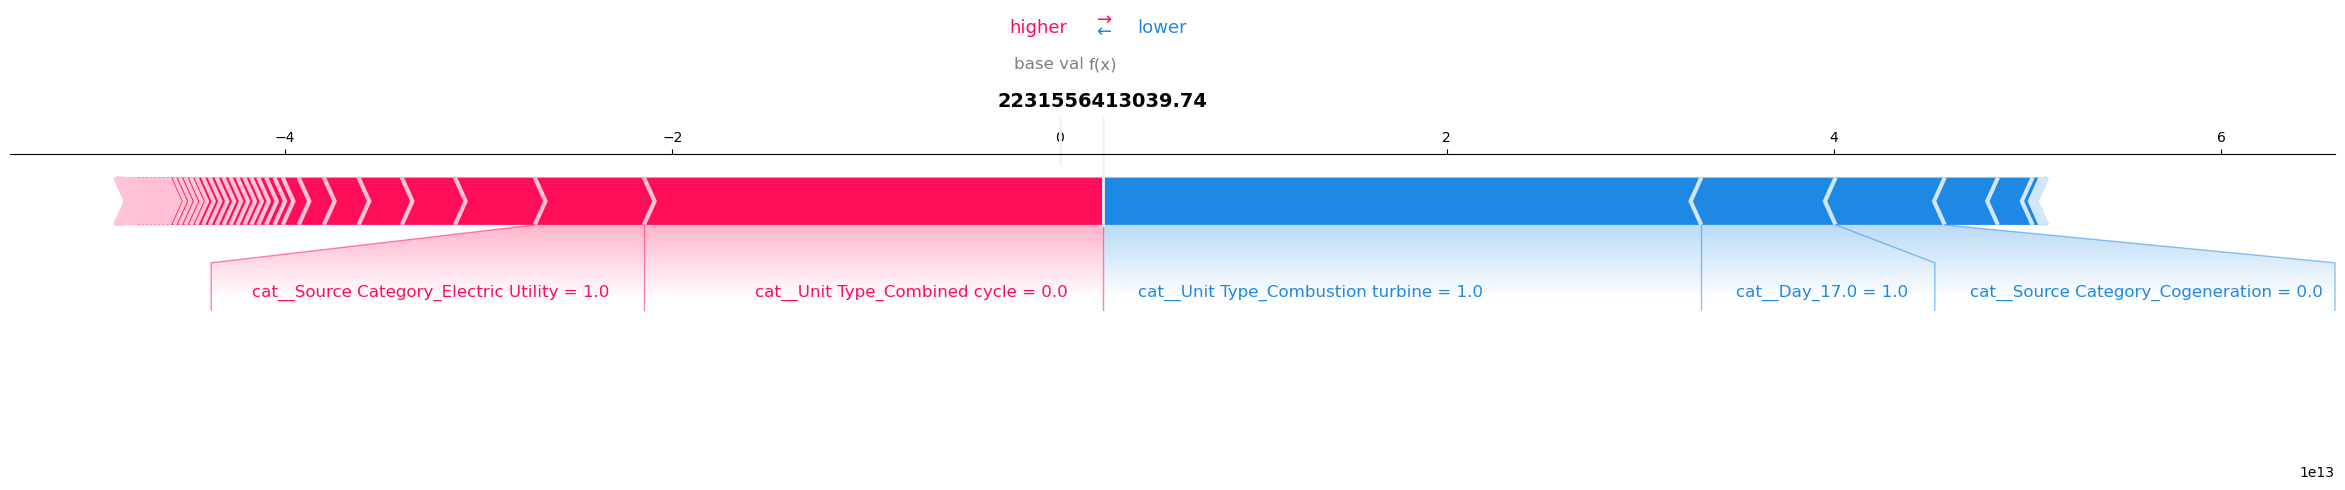

In [82]:
shap.plots.force(explainer(X_test.loc[[9582014]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

In [72]:
coefficients = pd.DataFrame({"Feature": X_sampled.columns, "Coefficient": np.transpose(lr_model.coef_)})
coefficients.sort_values(by="Coefficient", ascending=False).head(10)

,Feature,Coefficient
77,cat__Unit Type_Nothing,91759900186254.609375
83,cat__Primary Fuel Type_Wood,41113619494834.101562
69,cat__Source Category_Missing,22544169054093.242188
68,cat__Source Category_Electric Utility,22544169054050.863281
67,cat__Source Category_Cogeneration,22544169054035.066406
123,"encoded__Steam Injection (Retired Aug 02, 2022)",8608744457521.843750
111,"encoded__Dry Low NOx Burners (Began Jul 01, 2024)",2231556412935.428711
96,num__Heat Input (mmBtu),265.737057
115,encoded__Low NOx Burner Technology w/ Overfire...,119.523266
108,encoded__Combustion Modification/Fuel Reburning,104.993605


R^2 Score: -140973949304028512.0000
Mean Squared Error (MSE): 6000644779896077287424.0000
Root Mean Squared Error (RMSE): 77463828848.6703
Normalized RMSE (by std): 375875964.8081


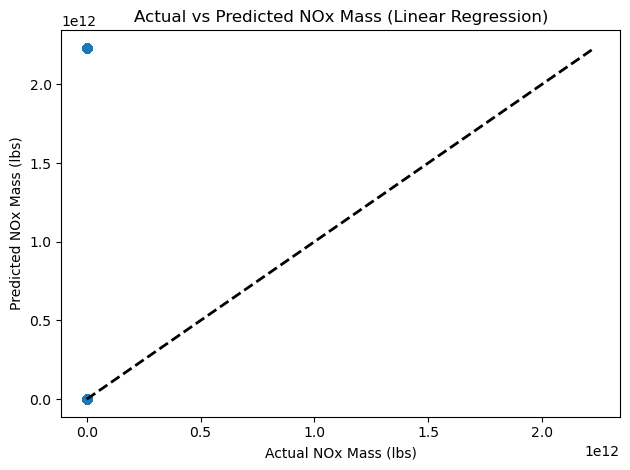

In [43]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_sampled, y_sampled)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



R^2 Score: 0.9537
Mean Squared Error (MSE): 1970.6852
Root Mean Squared Error (RMSE): 44.3924
Normalized RMSE (by std): 0.2154


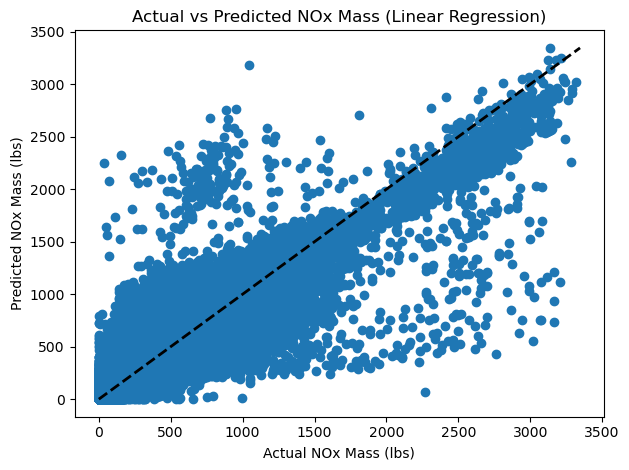

In [ ]:
# default model (with lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



<h3>Random Forest</h3>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [14]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners', 'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [17]:
# rf struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [9]:
X_sampled.shape

(1607705, 131)

In [ ]:
# still takes approx. 12 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1) 

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [11]:
joblib.dump(rf_model_no_lags, "TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json", compress=True)

['TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json']

In [6]:
rf_model_no_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9510
Mean Squared Error (MSE): 2065.5086
Root Mean Squared Error (RMSE): 45.4479
Normalized RMSE (by std): 0.2215


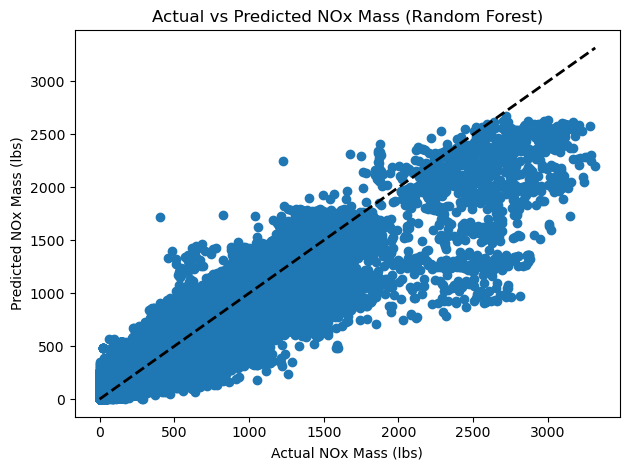

In [12]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [13]:
# compare performance across the imbalanced data
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for NOx Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for NOx Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 23.9939
RMSE for NOx Mass above 500 lbs: 169.7639


In [ ]:
# still takes approx. 10 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [19]:
joblib.dump(rf_model_with_lags, "TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json", compress=True)

['TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9848
Mean Squared Error (MSE): 639.2601
Root Mean Squared Error (RMSE): 25.2836
Normalized RMSE (by std): 0.1232


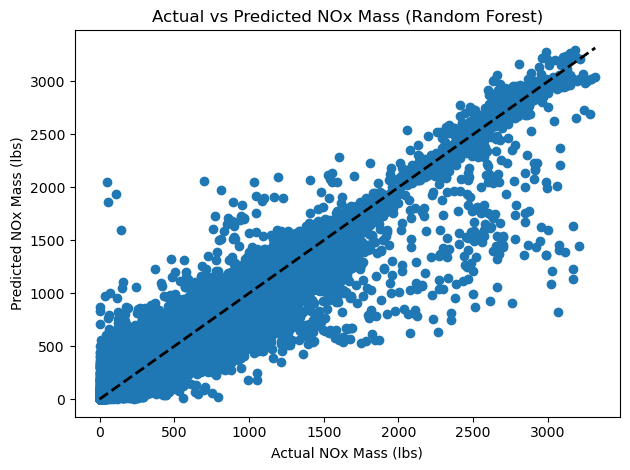

In [20]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
# compare performance across the imbalanced data
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for NOx Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for NOx Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 5.8653
RMSE for NOx Mass above 500 lbs: 72.5094


<h4>Scenario Analysis</h4>

In [ ]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test

y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test.values)[0]

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 1.21% which is reasonably low in relative terms
# about 1,952,759 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 159122698.9672
Total Actual NOx Mass (lbs): 161075458.7380
Relative Difference: -1.2123%
Total Difference: -1952759.7708


In [24]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1

# model with default parameters (no lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

y_pred_all_scr = rf_model_no_lags.predict(X_test_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [25]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 44.6923%
Total Difference: 71115581.4632


In [ ]:
# only about 50% of the entries in X_test had SCR
X_test["encoded__Selective Catalytic Reduction"].sum() / len(X_test)

0.516150635398621

<h3>MLP</h3>

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Ammonia Injection',
       'Combustion Modification/Fuel Reburning', 'Dry Low NOx Burners',
       'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', # removed other emissions (CO2, SO2) !!
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                #'unit_age_min',
                #'unit_age_max', 
                #'unit_age_mean', # removed gen ages because it likely works as a proxy for facility/unit id rather than causal age effects
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_train, y_train)

# using the full training data, this took 70mins

joblib.dump(mlp_default_model, "TX/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_tx_no_lags_no_unmeasured_with_temps.json", compress=True)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


['NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [ ]:
mlp_default_model = joblib.load("WY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_wy_no_lags_with_unmeasured_with_temps.json")

In [ ]:
# patch column mismatch of training and testing data
X_test["cat__Primary Fuel Type_Coal"] = 0
X_test["cat__Unit Type_Combined cycle (Started Feb 23, 2020)"] = 0
X_test = X_test[X_train.columns]

In [112]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.8431
Mean Squared Error (MSE): 577.6549
Root Mean Squared Error (RMSE): 24.0345
Normalized RMSE (by std): 0.3958


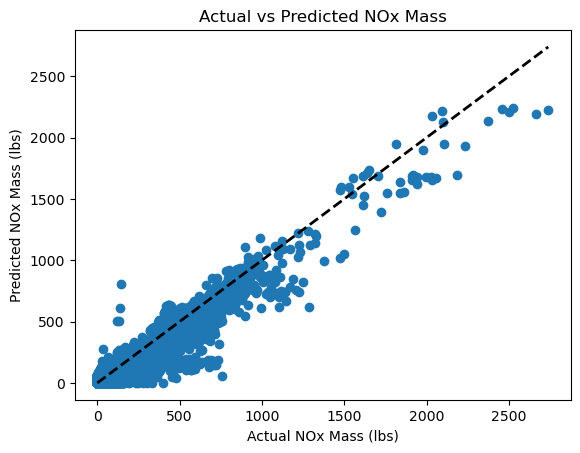

In [113]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing</h5>

In [ ]:
campd_tx["Day"] = campd_tx["datetime"].dt.day

In [ ]:
# read in previous year to get according lags
campd_tx_2018 = pd.read_csv("TX/Hourly/Before 2019/emissions-hourly-2018-tx.csv", dtype=campd_type_dict, date_format=["Date"])
campd_tx_2018 = campd_tx_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_tx_2018["datetime"] = pd.to_datetime(campd_tx_2018["Date"].astype(str) + ' ' + campd_tx_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_tx_2018["NOx Mass (lbs)"] = campd_tx_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_tx, campd_tx_2018, "NOx Mass (lbs)")

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [12]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [15]:
campd_df.shape

(14028675, 95)

In [18]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [19]:
campd_df.shape

(3563498, 95)

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [9]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", dtype=campd_type_dict)

In [21]:
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured                   2035031
Nothing                    1162797
Calculated                  186287
Measured and Substitute     106474
LME                          72482
Substitute                     427
Name: count, dtype: Int64

In [11]:
campd_df = campd_df[(campd_df["NOx Mass Measure Indicator"] == "Measured") | (campd_df["NOx Mass Measure Indicator"] == "Nothing")]
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured    8615784
Nothing     1142922
Name: count, dtype: Int64

In [12]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", dtype=campd_type_dict)

In [ ]:
# adjust time-dependent unit type entries (especially important to avoid ohe adding lots of unnecessary columns)
cols_to_adjust = ['Combustion turbine (Started Jul 01, 2024), Combined cycle (Ended Jul 01, 2024)',
                    'Combustion turbine (Started Jun 12, 2024), Combined cycle (Ended Jun 12, 2024)',
                                      'Combustion turbine (Started Dec 29, 2022)',
                                      'Combustion turbine (Started Jan 24, 2023)',
                                      'Combustion turbine (Started Nov 15, 2021)',
                                          'Combined cycle (Started Aug 30, 2020)',
                                          'Combined cycle (Started Sep 04, 2020)',
                                      'Combustion turbine (Started Mar 25, 2019)',
                                      'Combustion turbine (Started Apr 02, 2019)',
                                      'Combustion turbine (Started May 26, 2022)',
                                      'Combustion turbine (Started May 25, 2022)',
                                      'Combustion turbine (Started Sep 01, 2021)',
                                      'Combustion turbine (Started Jul 05, 2021)',
                                      'Combustion turbine (Started Aug 04, 2021)',
                                      'Combustion turbine (Started Jul 08, 2021)',
                                      'Combustion turbine (Started Jul 12, 2021)',
                                      'Combustion turbine (Started Sep 09, 2021)',
                                      'Combustion turbine (Started Aug 22, 2022)',
                                      'Combustion turbine (Started Jun 26, 2022)',
                                      'Combustion turbine (Started Mar 30, 2022)',
                                      'Combustion turbine (Started Mar 29, 2022)',
                                      'Combustion turbine (Started Mar 22, 2022)',
                                      'Combustion turbine (Started Mar 14, 2022)',
                                      'Combustion turbine (Started Mar 11, 2022)',
                                      'Combustion turbine (Started Mar 10, 2022)',
                                      'Combustion turbine (Started Sep 26, 2022)',
                                      'Combustion turbine (Started Sep 27, 2022)',
                                      'Combustion turbine (Started Sep 30, 2022)',
                                      'Combustion turbine (Started Oct 16, 2024)',
                                      'Combustion turbine (Started May 05, 2023)',
                                      'Combustion turbine (Started Apr 13, 2023)',
                                      'Combustion turbine (Started Apr 12, 2023)',
                                      'Combustion turbine (Started Apr 03, 2023)',
                                      'Combustion turbine (Started Mar 17, 2023)',
                                      'Combustion turbine (Started Mar 16, 2023)',
                                      'Combustion turbine (Started Jul 17, 2023)',
                                      'Combustion turbine (Started Aug 02, 2023)',
                                      'Combustion turbine (Started May 20, 2024)',
                                      'Combustion turbine (Started May 23, 2024)',
                                      'Combustion turbine (Started May 22, 2024)',
                                      'Combustion turbine (Started Aug 09, 2024)']

campd_df_to_adjust = campd_df[campd_df["Unit Type"].isin(cols_to_adjust)].copy()

campd_df_to_adjust["Unit Type"] = campd_df_to_adjust.apply(
    lambda row: parse_unit_type(row["Unit Type"], pd.to_datetime(row["datetime"])), axis=1
)

campd_df = pd.concat([
    campd_df[~(campd_df["Unit Type"].isin(cols_to_adjust))],       
    campd_df_to_adjust    
])

In [ ]:
campd_df["Unit Type"].unique()

array(['Combustion turbine', 'Dry bottom wall-fired boiler',
       'Tangentially-fired', 'Combined cycle',
       'Circulating fluidized bed boiler',
       'Bubbling fluidized bed boiler', 'Nothing'], dtype=object)

In [15]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [4]:
df_control_cols = ['Ammonia Injection',
       'Combustion Modification/Fuel Reburning', 'Dry Low NOx Burners',
       'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Closed-coupled/Separated OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Other', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Non-catalytic Reduction',
                                  'Steam Injection',
                                  'Steam Injection (Retired Aug 02, 2022)',
                                  'Steam Injection (Retired Jun 30, 2024)',
                                  'Water Injection', 'ARP', 'CSOSG2', 'MATS',
                                  'Missing', 'TXSO2'])])

In [ ]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train.gz", index=False, compression="gzip")
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test.gz", index=False, compression="gzip")
y_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_train.gz", index=False, compression="gzip")
y_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz", index=False, compression="gzip")

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train.gz", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test.gz", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_train.gz")
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz")

In [6]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.gz", index=False, compression="gzip")
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", index=False, compression="gzip")

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.gz", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", dtype=campd_type_dict)

In [14]:
print(y_test[X_test[X_test["cat__NOx Phase_Early Election"] == 1].index].sum())
print(y_test[X_test[X_test["cat__NOx Phase_Early Election"] == 0].index].sum())

73008841.85700001
88066616.88100006


In [15]:
print(y_test[X_test[X_test["cat__NOx Phase_Early Election"] == 1].index].mean())
print(y_test[X_test[X_test["cat__NOx Phase_Nothing"] == 1].index].mean())

504.89510419634587
55.89479980108891


In [ ]:
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

encoded_program_code_cols = ['encoded__ARP',
       'encoded__CSOSG2', 'encoded__MATS', 'encoded__Missing', 'encoded__TXSO2']
encoded_nox_phase_cols = ["cat__NOx Phase_Early Election", "cat__NOx Phase_Nothing"]

In [ ]:
X_train_adjusted = X_train.drop(columns=encoded_lag_cols)
X_train_adjusted = X_train_adjusted.drop(columns=encoded_program_code_cols)
X_train_adjusted = X_train_adjusted.drop(columns=encoded_nox_phase_cols)
X_train_adjusted = X_train_adjusted.drop(columns=['num__Latitude', 'num__Longitude'])

In [ ]:
X_test_adjusted = X_test.drop(columns=encoded_lag_cols)
X_test_adjusted = X_test_adjusted.drop(columns=encoded_program_code_cols)
X_test_adjusted = X_test_adjusted.drop(columns=encoded_nox_phase_cols)
X_test_adjusted = X_test_adjusted.drop(columns=['num__Latitude', 'num__Longitude'])


In [8]:
dtrain_adjusted = xgb.DMatrix(X_train_adjusted, label=y_train)
dtest_adjusted = xgb.DMatrix(X_test_adjusted, label=y_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [24]:
dtrain.save_binary("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_tx_full_2019_2023.buffer")
dtest.save_binary("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtest_tx_full_2024.buffer")

In [ ]:
dtrain = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_tx_full_2019_2023.buffer")
dtest = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtest_tx_full_2024.buffer")

In [10]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"tree_method": "auto", # uses approximation for large datasets
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

<h5>Different Time Series Tests</h5>

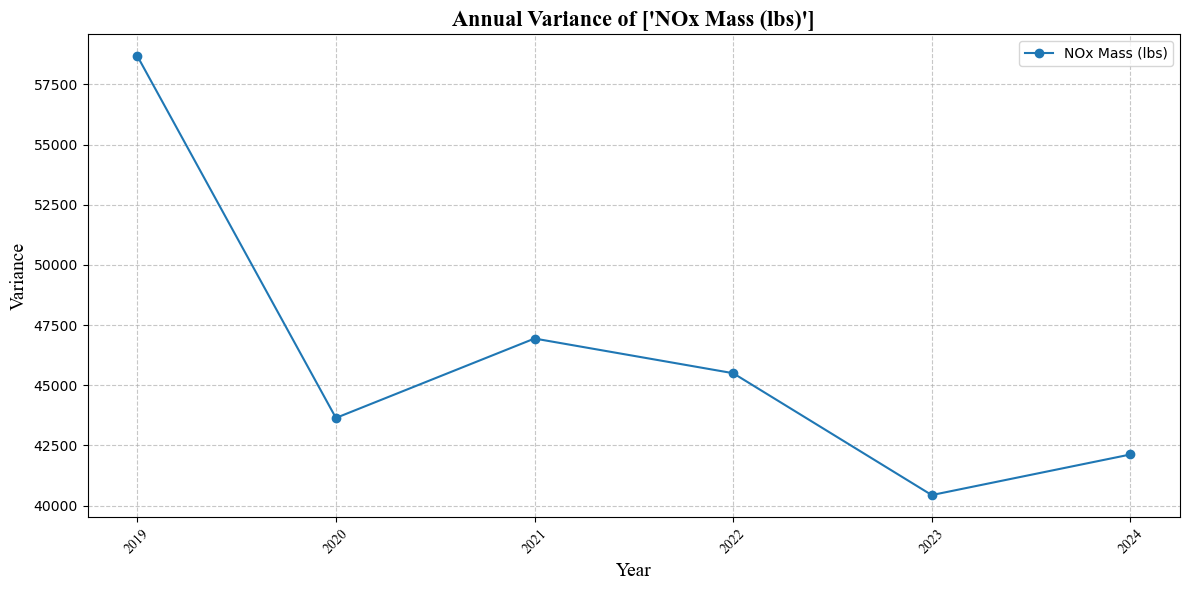

In [27]:
# Look at yearly variance 

variables = ["NOx Mass (lbs)"]

# Set 'datetime' as index for resampling
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])
campd_df.set_index('datetime', inplace=True)
annual_variance = campd_df[variables].resample('YE').var()
annual_variance.index = annual_variance.index.year

plt.figure(figsize=(12, 6))

for var in variables:
    plt.plot(annual_variance.index, annual_variance[var], marker='o', label=var)

plt.title(f'Annual Variance of {variables}', fontsize=16, fontweight='bold', fontname='Times New Roman')
plt.xlabel('Year', fontsize=14, fontname='Times New Roman')
plt.ylabel('Variance', fontsize=14, fontname='Times New Roman')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(annual_variance.index, rotation=45, fontname='Times New Roman')
plt.tight_layout()
plt.show()


In [5]:
df_control_cols = ['Ammonia Injection',
       'Combustion Modification/Fuel Reburning', 'Dry Low NOx Burners',
       'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                #'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    #'NOx Phase', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) #+ list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

In [10]:
# Year by Year

# without obvious proxies

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9388, MSE: 2668.8206, RMSE: 51.6606, nRMSE: 0.2470
Train: 2020, Test: 2021 | R^2: 0.9504, MSE: 2326.3271, RMSE: 48.2320, nRMSE: 0.2230
Train: 2021, Test: 2022 | R^2: 0.9453, MSE: 2485.5186, RMSE: 49.8550, nRMSE: 0.2336
Train: 2022, Test: 2023 | R^2: 0.9389, MSE: 2477.5146, RMSE: 49.7746, nRMSE: 0.2476
Train: 2023, Test: 2024 | R^2: 0.9530, MSE: 1981.6017, RMSE: 44.5152, nRMSE: 0.2170


In [11]:
# Rolling Window

# without obvious proxies

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2020 | R^2: 0.9388, MSE: 2668.8206, RMSE: 51.6606, nRMSE: 0.2470
Train: [2019, 2020], Test: 2021 | R^2: 0.9541, MSE: 2154.0449, RMSE: 46.4117, nRMSE: 0.2145
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9509, MSE: 2233.3838, RMSE: 47.2587, nRMSE: 0.2215
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9360, MSE: 2594.6946, RMSE: 50.9381, nRMSE: 0.2534
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9532, MSE: 1973.3765, RMSE: 44.4227, nRMSE: 0.2165


In [12]:
# Static Prediction Horizon (2024)

# without obvious proxies

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

Train: [2019], Test: 2024 | R^2: 0.8855, MSE: 4827.8804, RMSE: 69.4829, nRMSE: 0.3387
Train: [2019, 2020], Test: 2024 | R^2: 0.8969, MSE: 4348.9360, RMSE: 65.9465, nRMSE: 0.3214
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9184, MSE: 3442.6582, RMSE: 58.6742, nRMSE: 0.2860
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9289, MSE: 2997.6650, RMSE: 54.7509, nRMSE: 0.2669
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9532, MSE: 1973.3765, RMSE: 44.4227, nRMSE: 0.2165


In [14]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9387, MSE: 2673.6353, RMSE: 51.7072, nRMSE: 0.2472
Train: 2020, Test: 2021 | R^2: 0.9513, MSE: 2284.4434, RMSE: 47.7959, nRMSE: 0.2209
Train: 2021, Test: 2022 | R^2: 0.9468, MSE: 2418.0630, RMSE: 49.1738, nRMSE: 0.2305
Train: 2022, Test: 2023 | R^2: 0.9357, MSE: 2606.8848, RMSE: 51.0577, nRMSE: 0.2540
Train: 2023, Test: 2024 | R^2: 0.9531, MSE: 1977.7496, RMSE: 44.4719, nRMSE: 0.2168


In [15]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9387, MSE: 2673.6353, RMSE: 51.7072, nRMSE: 0.2472
Train: [2019, 2020], Test: 2021 | R^2: 0.9552, MSE: 2102.9565, RMSE: 45.8580, nRMSE: 0.2120
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9509, MSE: 2232.8052, RMSE: 47.2526, nRMSE: 0.2215
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9367, MSE: 2564.0693, RMSE: 50.6366, nRMSE: 0.2519
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9536, MSE: 1956.7382, RMSE: 44.2350, nRMSE: 0.2156


In [16]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.8890, MSE: 4682.1694, RMSE: 68.4264, nRMSE: 0.3335
Train: [2019, 2020], Test: 2024 | R^2: 0.9051, MSE: 4002.8960, RMSE: 63.2684, nRMSE: 0.3084
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9161, MSE: 3537.7710, RMSE: 59.4792, nRMSE: 0.2899
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9237, MSE: 3216.4670, RMSE: 56.7139, nRMSE: 0.2764
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9536, MSE: 1956.7382, RMSE: 44.2350, nRMSE: 0.2156


In [ ]:
# comparison between the two models

r2_1 = [0.9388, 0.9504, 0.9453, 0.9389, 0.9530]
mse_1 = [2668.8206, 2326.3271, 2485.5186, 2477.5146, 1981.6017]
rmse_1 = [51.6606, 48.2320, 49.8550, 49.7746, 44.5152]
nrmse_1 = [0.2470, 0.2230, 0.2336, 0.2476, 0.2170]

r2_2 = [0.9387, 0.9513, 0.9468, 0.9357, 0.9531]
mse_2 = [2673.6353, 2284.4434, 2418.0630, 2606.8848, 1977.7496]
rmse_2 = [51.7072, 47.7959, 49.1738, 51.0577, 44.4719]
nrmse_2 = [0.2472, 0.2209, 0.2305, 0.2540, 0.2168]

def avg(lst): return sum(lst) / len(lst)

avg_r2_1 = avg(r2_1)
avg_mse_1 = avg(mse_1)
avg_rmse_1 = avg(rmse_1)
avg_nrmse_1 = avg(nrmse_1)

avg_r2_2 = avg(r2_2)
avg_mse_2 = avg(mse_2)
avg_rmse_2 = avg(rmse_2)
avg_nrmse_2 = avg(nrmse_2)

diff_r2 = avg_r2_2 - avg_r2_1
diff_mse = avg_mse_2 - avg_mse_1
diff_rmse = avg_rmse_2 - avg_rmse_1
diff_nrmse = avg_nrmse_2 - avg_nrmse_1

print("Average Comparison for Year by Year:")
print(f"R2: Set1={avg_r2_1:.4f}, Set2={avg_r2_2:.4f}, Diff={diff_r2:+.4f}")
print(f"MSE: Set1={avg_mse_1:.4f}, Set2={avg_mse_2:.4f}, Diff={diff_mse:+.4f}")
print(f"RMSE: Set1={avg_rmse_1:.4f}, Set2={avg_rmse_2:.4f}, Diff={diff_rmse:+.4f}")
print(f"nRMSE: Set1={avg_nrmse_1:.4f}, Set2={avg_nrmse_2:.4f}, Diff={diff_nrmse:+.4f}")

r2_cum_1 = [0.9388, 0.9541, 0.9509, 0.9360, 0.9532]
mse_cum_1 = [2668.8206, 2154.0449, 2233.3838, 2594.6946, 1973.3765]
rmse_cum_1 = [51.6606, 46.4117, 47.2587, 50.9381, 44.4227]
nrmse_cum_1 = [0.2470, 0.2145, 0.2215, 0.2534, 0.2165]

r2_cum_2 = [0.9387, 0.9552, 0.9509, 0.9367, 0.9536]
mse_cum_2 = [2673.6353, 2102.9565, 2232.8052, 2564.0693, 1956.7382]
rmse_cum_2 = [51.7072, 45.8580, 47.2526, 50.6366, 44.2350]
nrmse_cum_2 = [0.2472, 0.2120, 0.2215, 0.2519, 0.2156]

avg_r2_cum_1 = avg(r2_cum_1)
avg_mse_cum_1 = avg(mse_cum_1)
avg_rmse_cum_1 = avg(rmse_cum_1)
avg_nrmse_cum_1 = avg(nrmse_cum_1)

avg_r2_cum_2 = avg(r2_cum_2)
avg_mse_cum_2 = avg(mse_cum_2)
avg_rmse_cum_2 = avg(rmse_cum_2)
avg_nrmse_cum_2 = avg(nrmse_cum_2)

diff_r2 = avg_r2_cum_2 - avg_r2_cum_1
diff_mse = avg_mse_cum_2 - avg_mse_cum_1
diff_rmse = avg_rmse_cum_2 - avg_rmse_cum_1
diff_nrmse = avg_nrmse_cum_2 - avg_nrmse_cum_1

print("\nAverages Comparison for Rolling Window:")
print(f"R2: Set1={avg_r2_cum_1:.4f}, Set2={avg_r2_cum_2:.4f}, Diff={diff_r2:+.4f}")
print(f"MSE: Set1={avg_mse_cum_1:.4f}, Set2={avg_mse_cum_2:.4f}, Diff={diff_mse:+.4f}")
print(f"RMSE: Set1={avg_rmse_cum_1:.4f}, Set2={avg_rmse_cum_2:.4f}, Diff={diff_rmse:+.4f}")
print(f"nRMSE: Set1={avg_nrmse_cum_1:.4f}, Set2={avg_nrmse_cum_2:.4f}, Diff={diff_nrmse:+.4f}")

r2_set1 = [0.8855, 0.8969, 0.9184, 0.9289, 0.9532]
mse_set1 = [4827.8804, 4348.9360, 3442.6582, 2997.6650, 1973.3765]
rmse_set1 = [69.4829, 65.9465, 58.6742, 54.7509, 44.4227]
nrmse_set1 = [0.3387, 0.3214, 0.2860, 0.2669, 0.2165]

r2_set2 = [0.8890, 0.9051, 0.9161, 0.9237, 0.9536]
mse_set2 = [4682.1694, 4002.8960, 3537.7710, 3216.4670, 1956.7382]
rmse_set2 = [68.4264, 63.2684, 59.4792, 56.7139, 44.2350]
nrmse_set2 = [0.3335, 0.3084, 0.2899, 0.2764, 0.2156]

avg_r2_1 = avg(r2_set1)
avg_mse_1 = avg(mse_set1)
avg_rmse_1 = avg(rmse_set1)
avg_nrmse_1 = avg(nrmse_set1)

avg_r2_2 = avg(r2_set2)
avg_mse_2 = avg(mse_set2)
avg_rmse_2 = avg(rmse_set2)
avg_nrmse_2 = avg(nrmse_set2)

diff_r2 = avg_r2_2 - avg_r2_1
diff_mse = avg_mse_2 - avg_mse_1
diff_rmse = avg_rmse_2 - avg_rmse_1
diff_nrmse = avg_nrmse_2 - avg_nrmse_1

print("\nAverage Comparison Static Prediction Horizon (2024)")
print(f"R2: Set1={avg_r2_1:.4f}, Set2={avg_r2_2:.4f}, Diff={diff_r2:+.4f}")
print(f"MSE: Set1={avg_mse_1:.4f}, Set2={avg_mse_2:.4f}, Diff={diff_mse:+.4f}")
print(f"RMSE: Set1={avg_rmse_1:.4f}, Set2={avg_rmse_2:.4f}, Diff={diff_rmse:+.4f}")
print(f"nRMSE: Set1={avg_nrmse_1:.4f}, Set2={avg_nrmse_2:.4f}, Diff={diff_nrmse:+.4f}")

Average Comparison for Year by Year:
R2: Set1=0.9453, Set2=0.9451, Diff=-0.0002
MSE: Set1=2387.9565, Set2=2392.1552, Diff=+4.1987
RMSE: Set1=48.8075, Set2=48.8413, Diff=+0.0338
nRMSE: Set1=0.2336, Set2=0.2339, Diff=+0.0002

Averages Comparison for Rolling Window:
R2: Set1=0.9466, Set2=0.9470, Diff=+0.0004
MSE: Set1=2324.8641, Set2=2306.0409, Diff=-18.8232
RMSE: Set1=48.1384, Set2=47.9379, Diff=-0.2005
nRMSE: Set1=0.2306, Set2=0.2296, Diff=-0.0009

Average Comparison Static Prediction Horizon (2024)
R2: Set1=0.9166, Set2=0.9175, Diff=+0.0009
MSE: Set1=3518.1032, Set2=3479.2083, Diff=-38.8949
RMSE: Set1=58.6554, Set2=58.4246, Diff=-0.2309
nRMSE: Set1=0.2859, Set2=0.2848, Diff=-0.0011


In [ ]:
# Time Series Split

# conducted on dataset with lags, no unmeasured, with temps

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=17, RMSE=14.1850, R2=0.9437
Fold 2: best_iteration=111, RMSE=10.0866, R2=0.9717
Fold 3: best_iteration=69, RMSE=11.1816, R2=0.9752
Fold 4: best_iteration=34, RMSE=11.8458, R2=0.9634
Fold 5: best_iteration=139, RMSE=7.8996, R2=0.9800

Optimal num_boost_round (avg): 74
Average RMSE across folds: 11.0397
Average R2 across folds: 0.9668


<h5>Train All, Test Year 2024</h5>

In [ ]:
# Stakeholders must balance predictive performance with feature causality/generalizability
# e. g. for a scenario analysis it may be hurtful if correlations like a program code applying to higher emissions
# are forcefully generalized by the model

R^2 Score: 0.9532
Mean Squared Error (MSE): 1973.3765
Root Mean Squared Error (RMSE): 44.4227
Normalized RMSE (by std): 0.2163


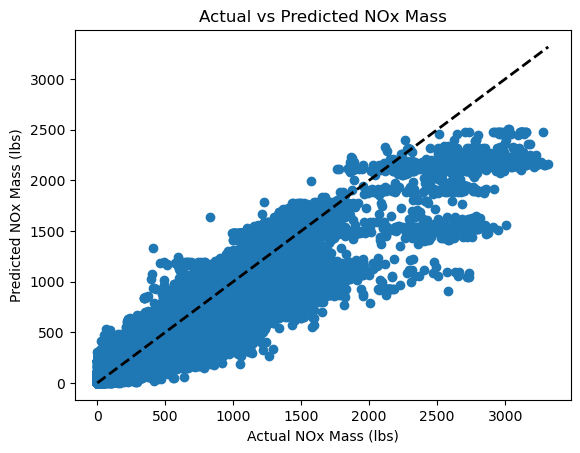

In [11]:
# model with default parameters (no lags, no unmeasured data, with temps)

# excludes columns for NOx phase, program code, AND coordinates

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_adjusted, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.json")

y_pred = xgb_default_model.predict(dtest_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9532
Mean Squared Error (MSE): 1973.3765
Root Mean Squared Error (RMSE): 44.4227
Normalized RMSE (by std): 0.2163


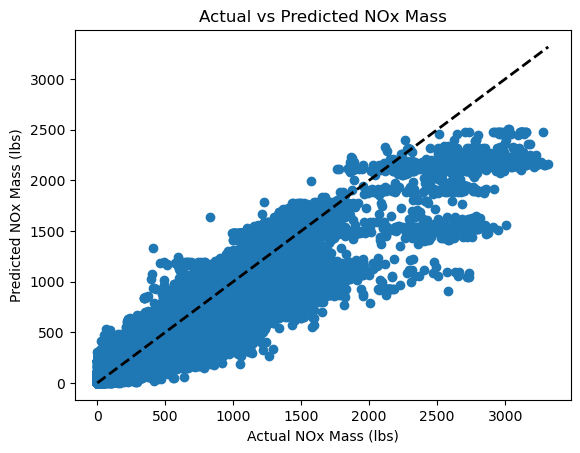

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# excludes columns for NOx phase, program code, AND coordinates

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_adjusted, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.json")

y_pred = xgb_default_model.predict(dtest_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model)

In [36]:
shap_values = explainer(X_test_adjusted, approximate=False)

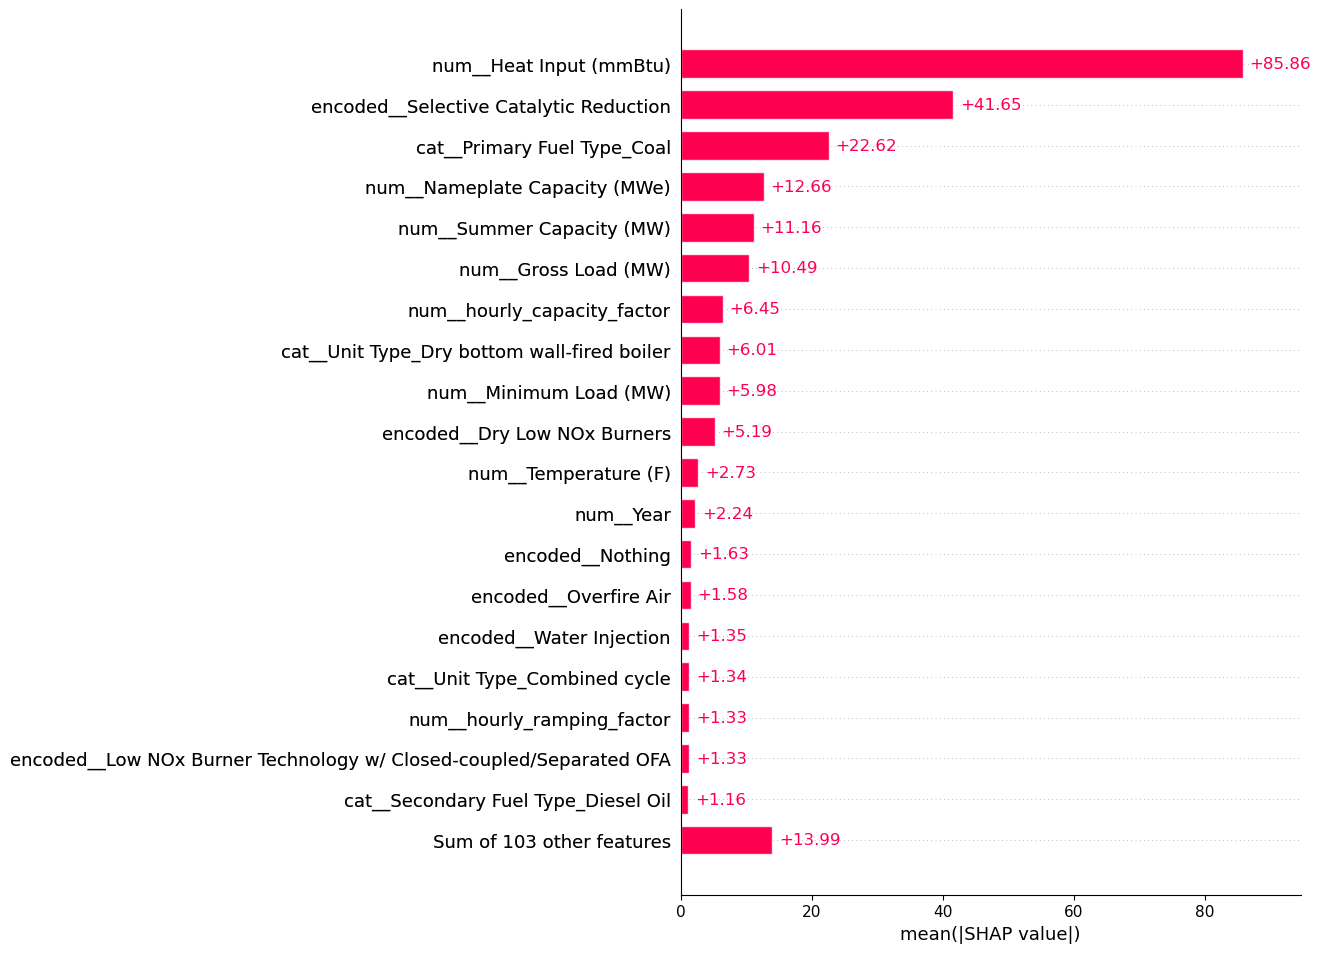

In [37]:
shap.plots.bar(shap_values, max_display=20) 

R^2 Score: 0.9536
Mean Squared Error (MSE): 1956.7382
Root Mean Squared Error (RMSE): 44.2350
Normalized RMSE (by std): 0.2154


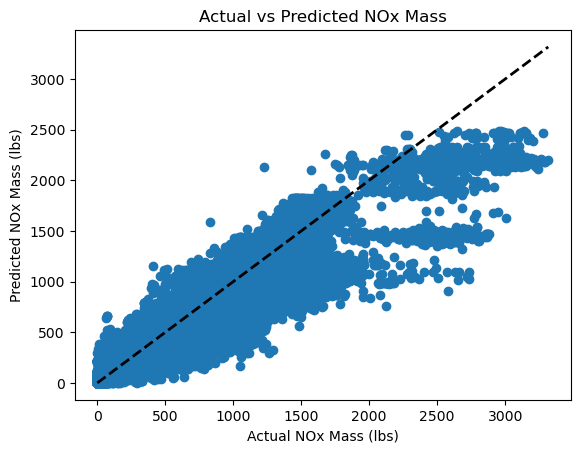

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9826
Mean Squared Error (MSE): 732.4965
Root Mean Squared Error (RMSE): 27.0647
Normalized RMSE (by std): 0.1318


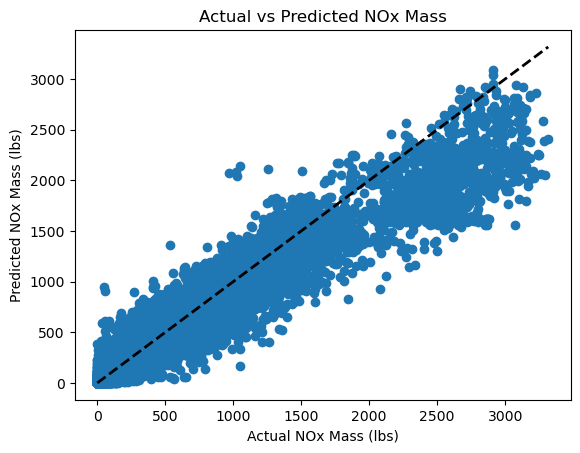

In [26]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [47]:
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for NOx Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for NOx Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 5.7844
RMSE for NOx Mass above 500 lbs: 83.2018


<h5>Scenario Analysis</h5>

In [42]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test


In [ ]:
y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 1.75% which is reasonably low in relative terms
# about 2,823,908 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 158251549.8855
Total Actual NOx Mass (lbs): 161075458.7313
Relative Difference: -1.7532%
Total Difference: -2823908.8458


In [44]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test.copy()
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1
dtest_all_SCR = xgb.DMatrix(X_test_all_SCR, label=y_test)

In [46]:
# predict on data with all SCR = 1

y_pred_all_scr = xgb_default_model_no_lags.predict(dtest_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [47]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 41.0744%
Total Difference: 65000912.0000


<h5>HPO</h5>

<h6>Optuna Trials</h6>

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    "device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "tree_method": "hist",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        #"device": "cuda"  # or "cpu"
    }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [ ]:
study = optuna.create_study(study_name="HPT 22.06.25 18:04", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")

second_best_params = sorted_trials[1]


In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

<h6>Model</h6>

In [36]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
# second best params found
second_best_hpo_params = {
    **second_best_params.params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}


In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

In [ ]:
# model with second best (less boost rounds) hpo parameters (with lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=second_best_hpo_params, dtrain=dtrain, num_boost_round=254)

# dump model
xgb_hpo_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
# model with best hpo parameters (no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=570)

# dump model
#xgb_hpo_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained/Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [7]:
# load saved models

rf_default_model_no_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps.json")


In [ ]:
xgb_default_model_no_lags_no_phase_code_coords = xgb.Booster()
xgb_default_model_no_lags_no_phase_code_coords.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.json")

In [14]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags_no_phase_code_coords)

In [ ]:
X_test_sample = X_test_adjusted.sample(n=100000, random_state=42)

interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 50 mins

In [ ]:
# DUE TO OVERRELIANCE ON PROXY VARIABLES WE REMOVED THEM
# SHOULDNT BE A BIG ISSUE FOR THE OTHER MODELS SINCE THEY BARELY RELY ON THEM

In [ ]:
joblib.dump(interaction_values_shap, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.pkl")

In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")

<h3>RF (model-specific)</h3>

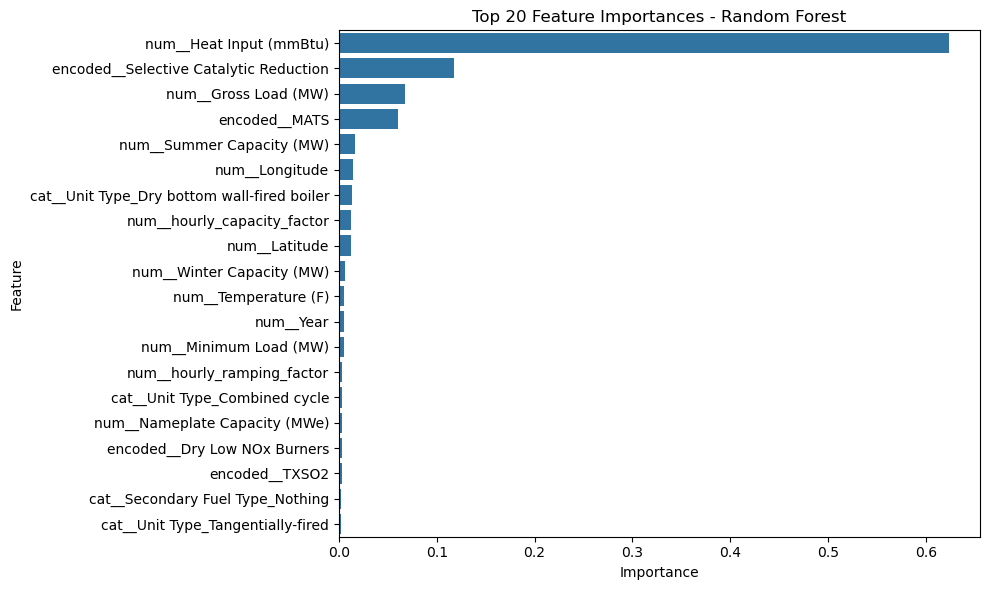

In [8]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


In [ ]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

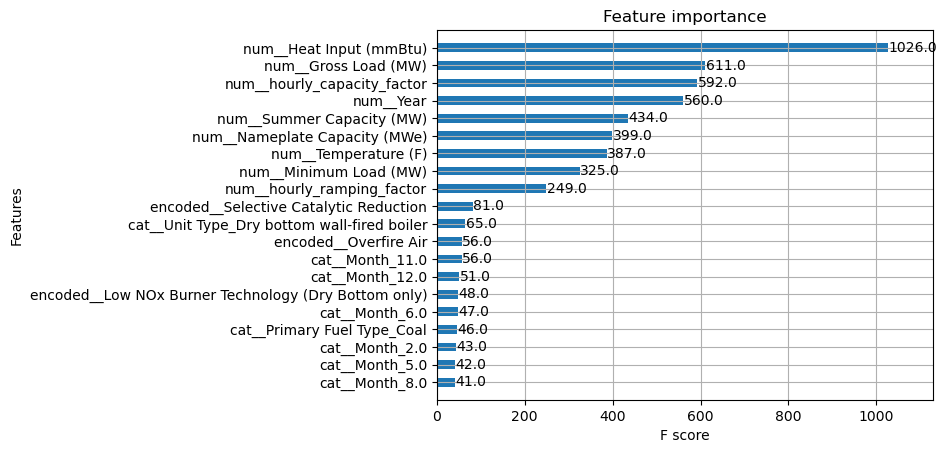

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

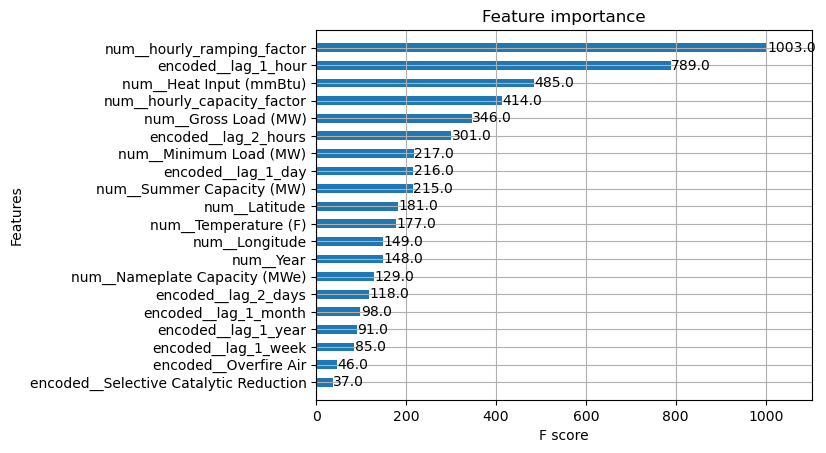

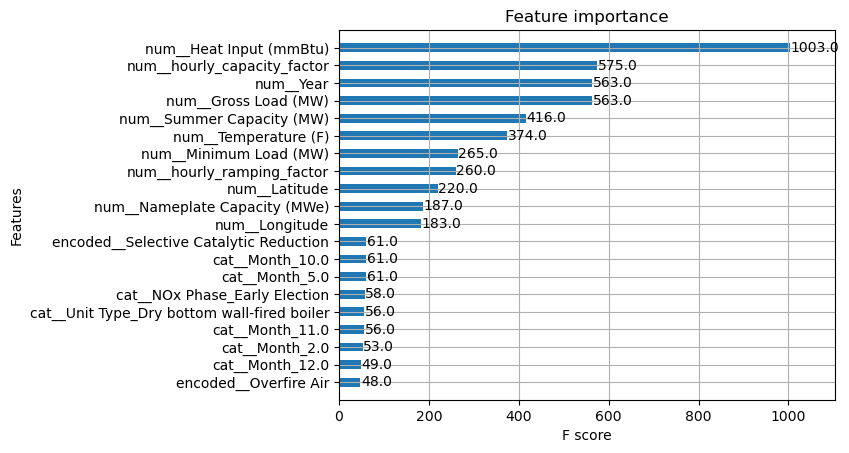

In [18]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

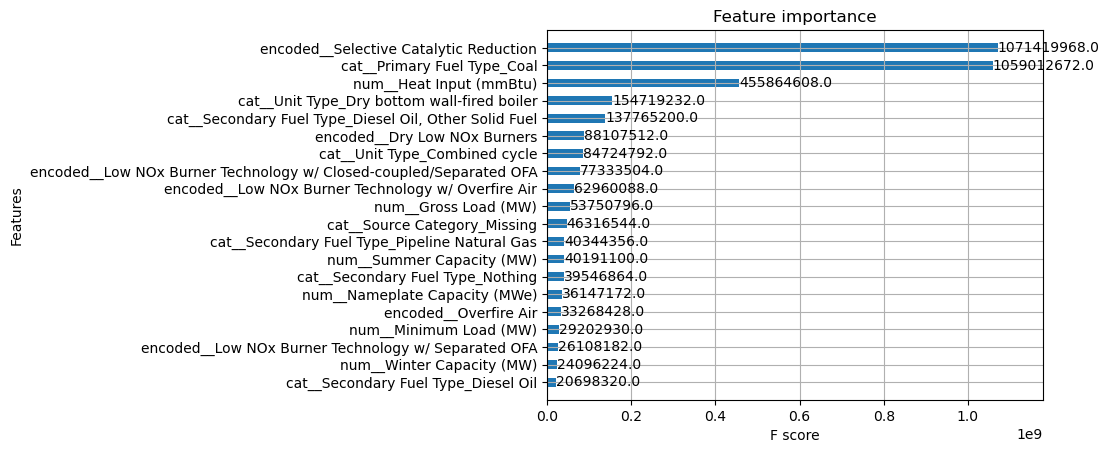

In [6]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

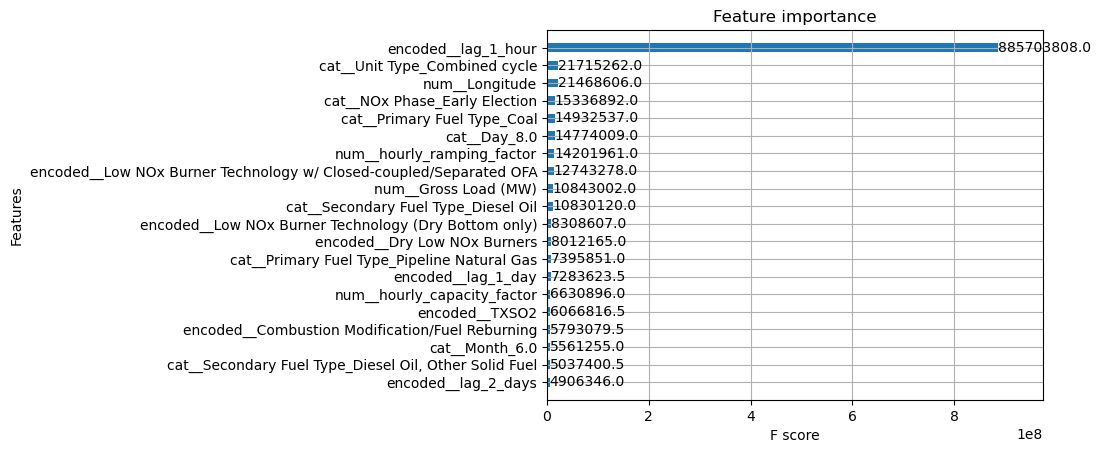

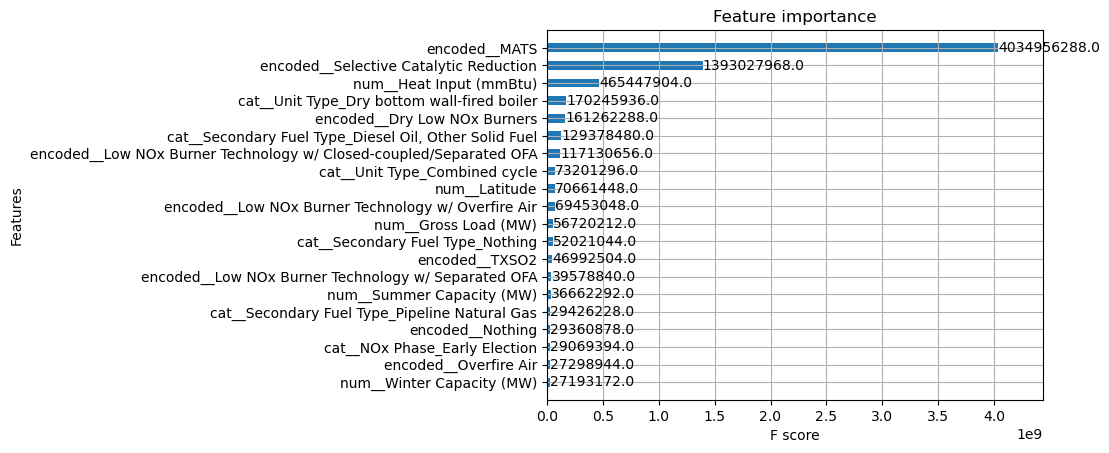

In [19]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

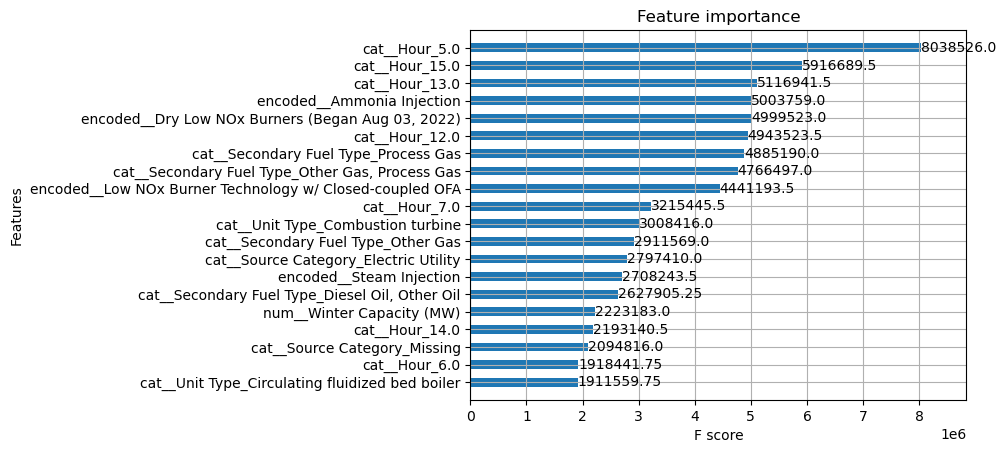

In [7]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

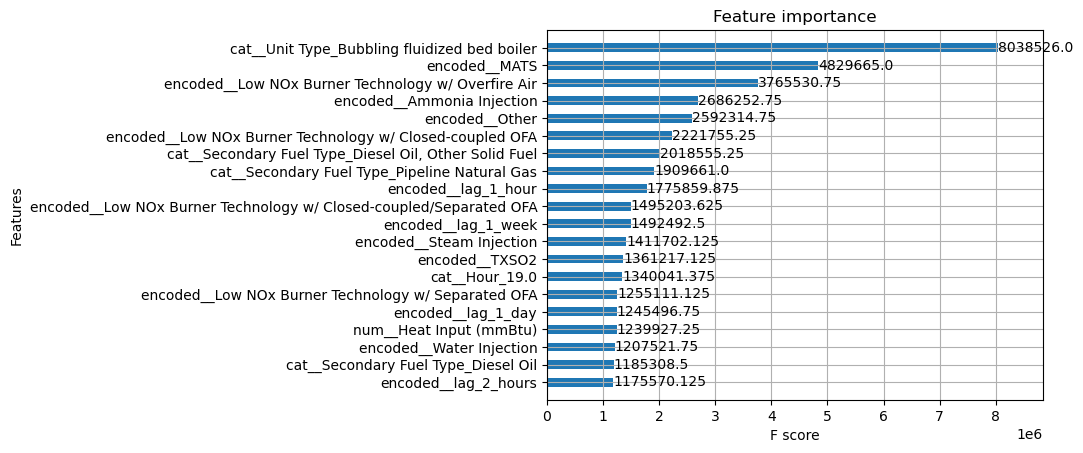

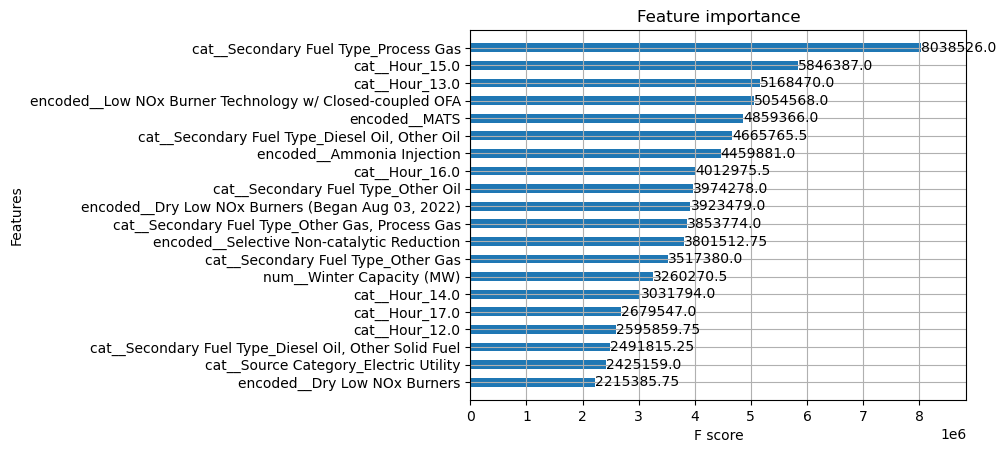

In [20]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h5>HPO Params</h5>

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_hpo_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

In [8]:
xgb_default_model_no_lags_regressor = XGBRegressor()
xgb_default_model_no_lags_regressor._Booster = xgb_default_model_no_lags

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [8]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags_no_phase_code_coords

In [ ]:
result = permutation_importance(regressor, X_test_adjusted, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test_adjusted.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)

# took 12 mins


,feature,importance_mean,importance_std
94,num__Heat Input (mmBtu),60409.084603,81.705502
116,encoded__Selective Catalytic Reduction,17003.643351,24.679094
95,num__Nameplate Capacity (MWe),13401.710313,41.738102
77,cat__Primary Fuel Type_Coal,7082.210391,10.728937
93,num__Gross Load (MW),5067.891875,27.604198
...,...,...,...
45,cat__Day_10.0,-0.077071,0.087263
62,cat__Day_27.0,-0.088003,0.007455
52,cat__Day_17.0,-0.919157,0.061975
0,cat__Month_1.0,-2.674175,0.083400


<h4>Ungrouped</h4>

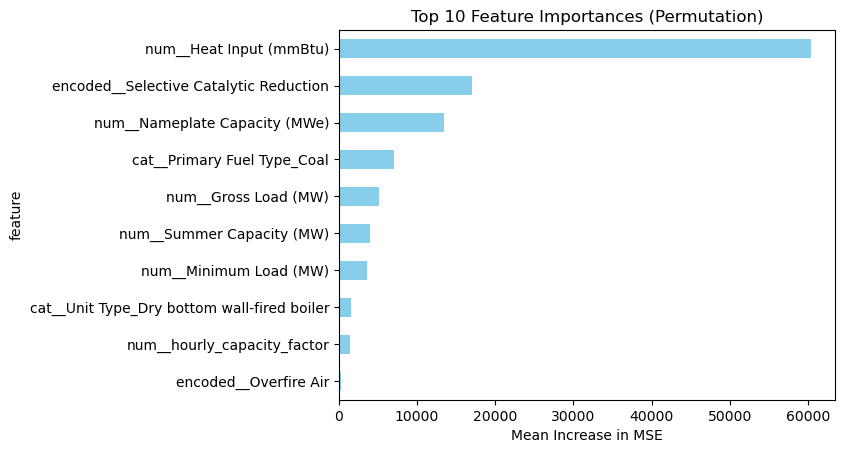

In [20]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [19]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

In [ ]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/y_test")

In [21]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

In [ ]:
xgb_default_model_no_corr = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model_no_corr.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [25]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_corr

In [26]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error')

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


<h4>Grouped</h4>

In [ ]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>RF</h4>

In [6]:
explainer = shap.TreeExplainer(rf_default_model_no_lags)

In [7]:
# takes over 15 mins without approximation
shap_values = explainer(X_test, approximate=True)

In [ ]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

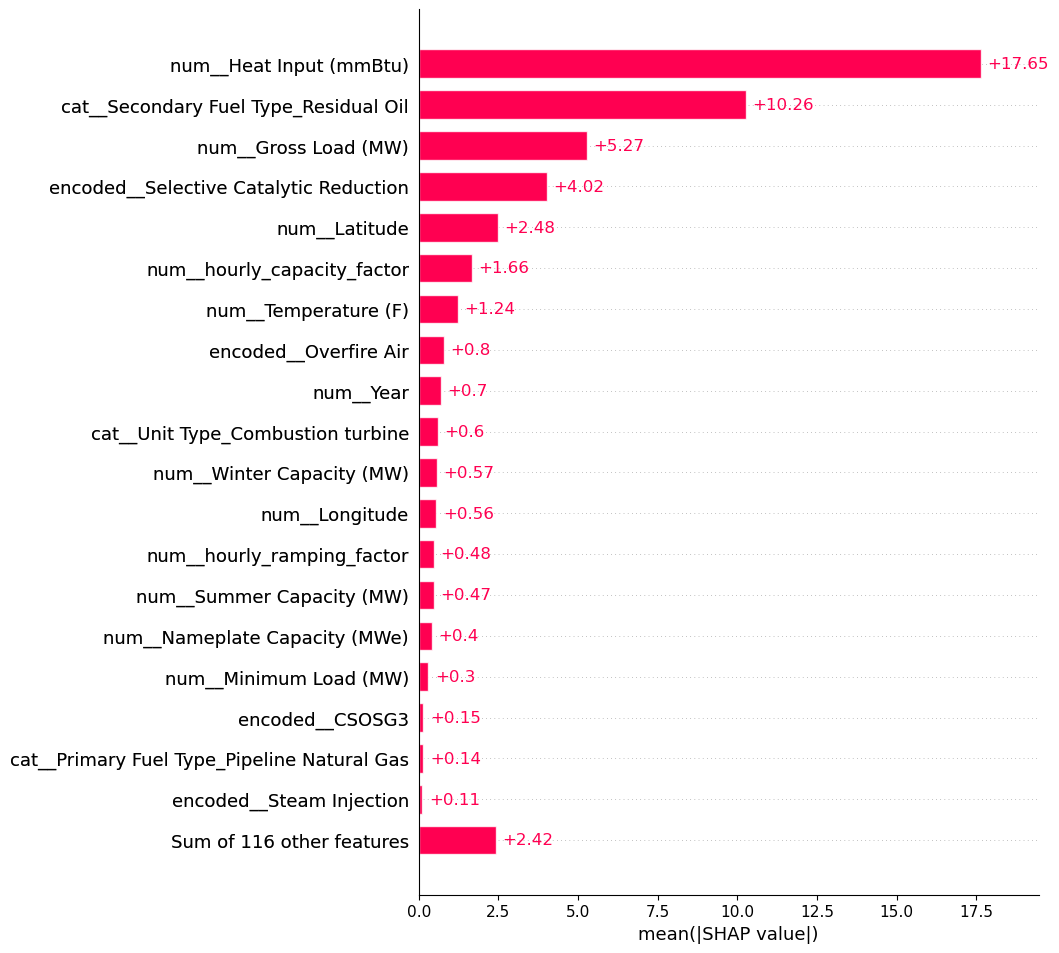

In [9]:
shap.plots.bar(shap_values, max_display=20)

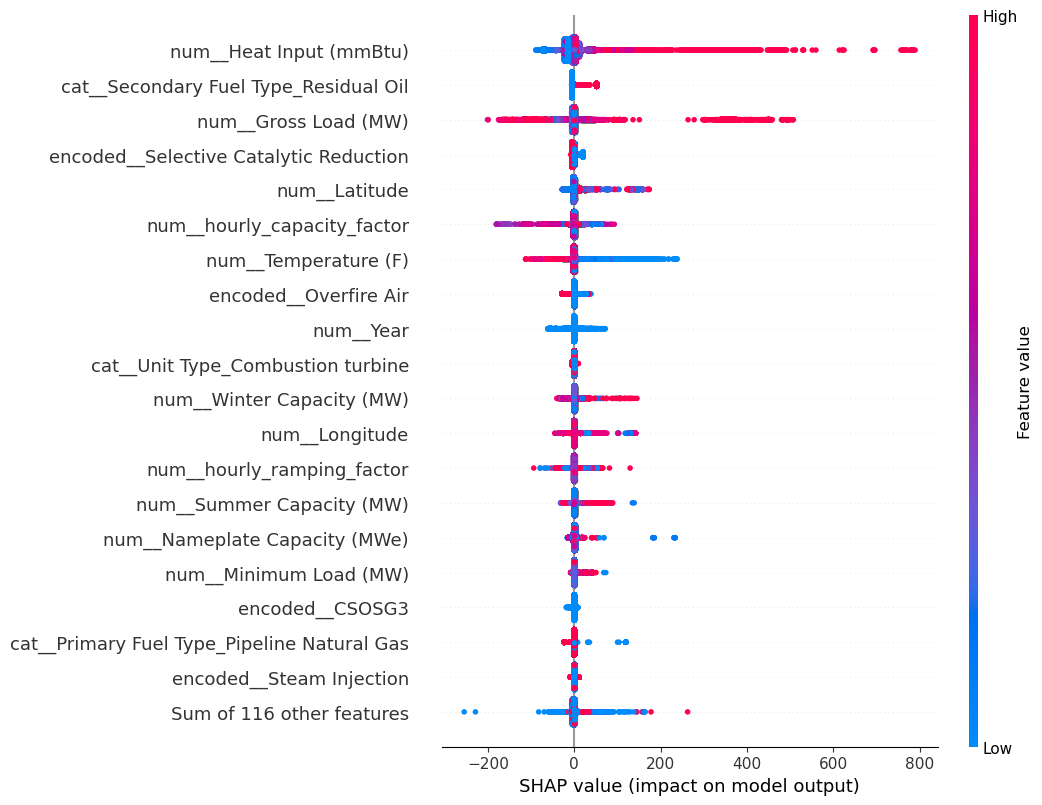

In [10]:
shap.plots.beeswarm(shap_values, max_display=20)

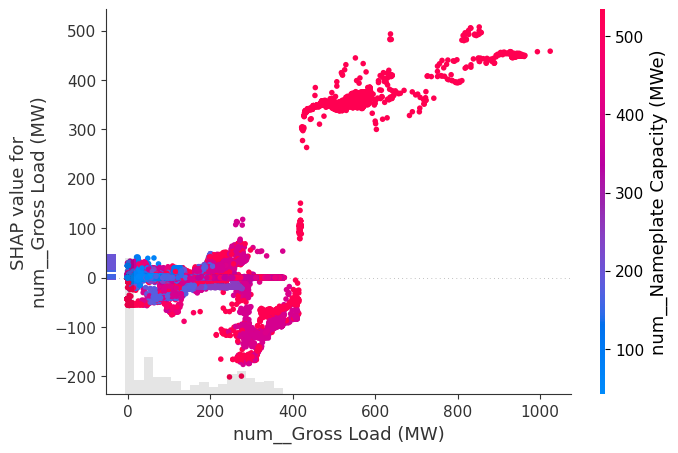

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

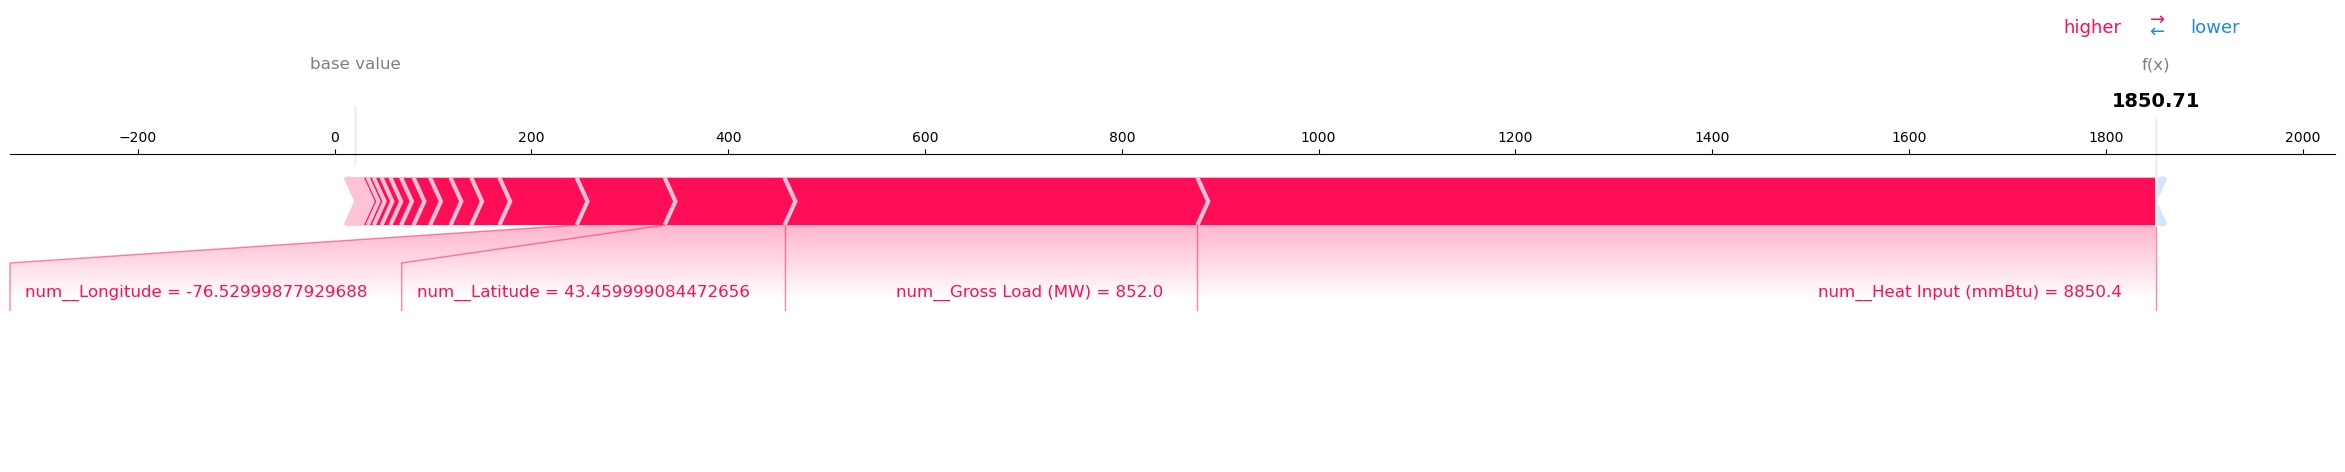

In [12]:

# Fit model and select a single sample
# Show force plot
shap.plots.force(explainer(X_test.iloc[[482884]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

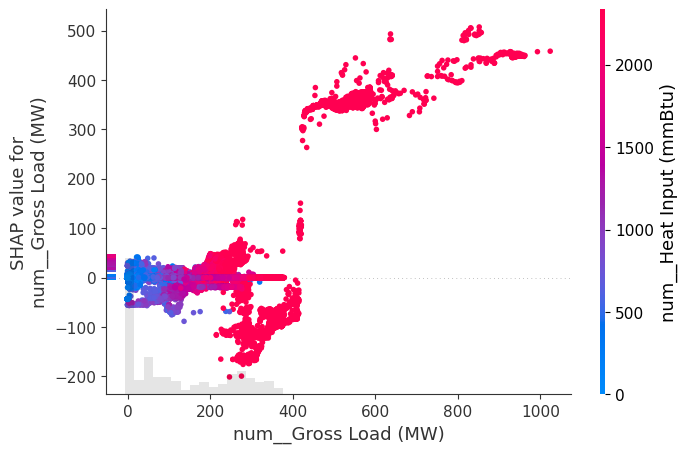

In [33]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


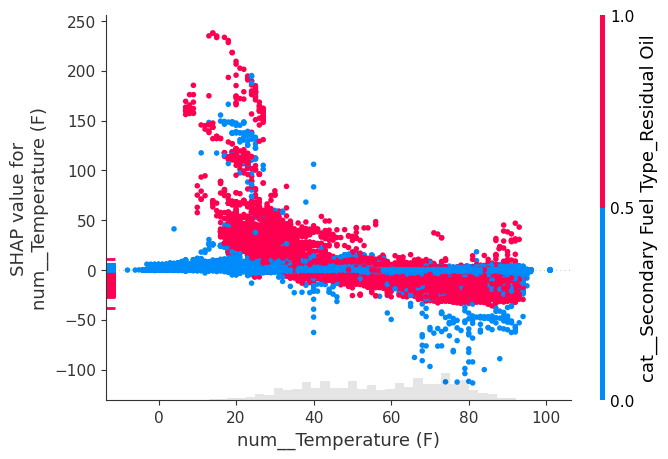

In [32]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Temperature (F)"])


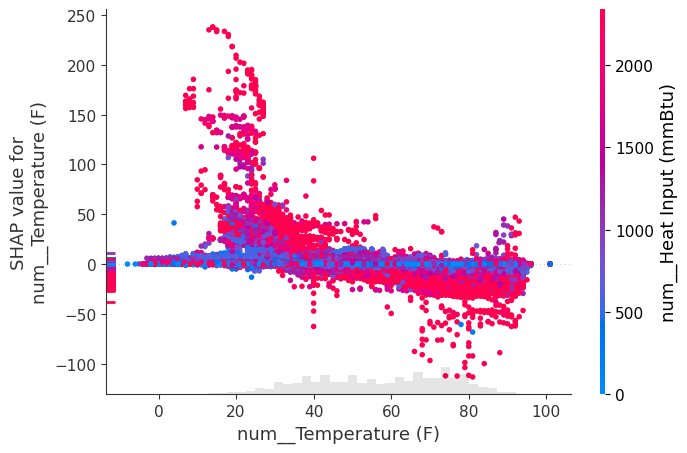

In [31]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


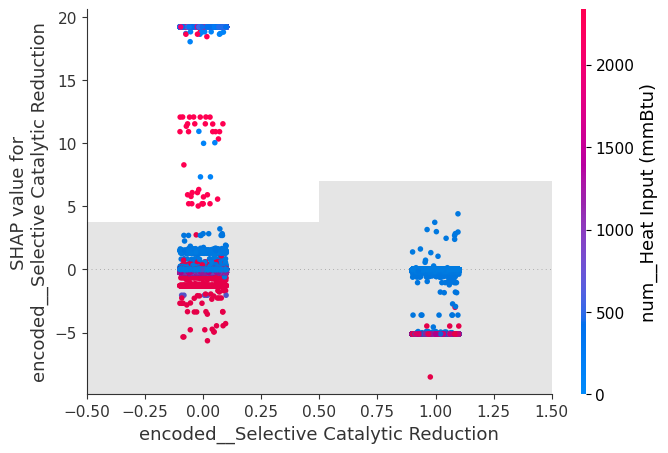

In [24]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])


lime test

In [ ]:
import lime
from lime.lime_tabular import LimeTabularExplainer

In [ ]:
# Initialize the LIME explainer
explainer = LimeTabularExplainer(
    training_data=np.array(X_train_adjusted),
    feature_names=X_train_adjusted.columns.tolist(),
    mode='regression'
)

# Explain the prediction
exp = explainer.explain_instance(
    data_row=X_test_adjusted.iloc[0].values,
    predict_fn=xgb_default_model_no_lags_no_phase_code_coords.predict
)

# Show explanation in notebook
exp.show_in_notebook(show_table=True)

<h4>XGB</h4>

<h5>SHAP Values</h5>

In [9]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [ ]:
shap_values = explainer(X_test, approximate=False)

# this took just 3mins

In [12]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

In [ ]:
X_test[(X_test["encoded__MATS"] == 1)]["cat__Primary Fuel Type_Coal"].sum() / len(X_test[(X_test["encoded__MATS"] == 1)])

# MATS worked as a proxy for Primary Fuel Type Coal !

1.0

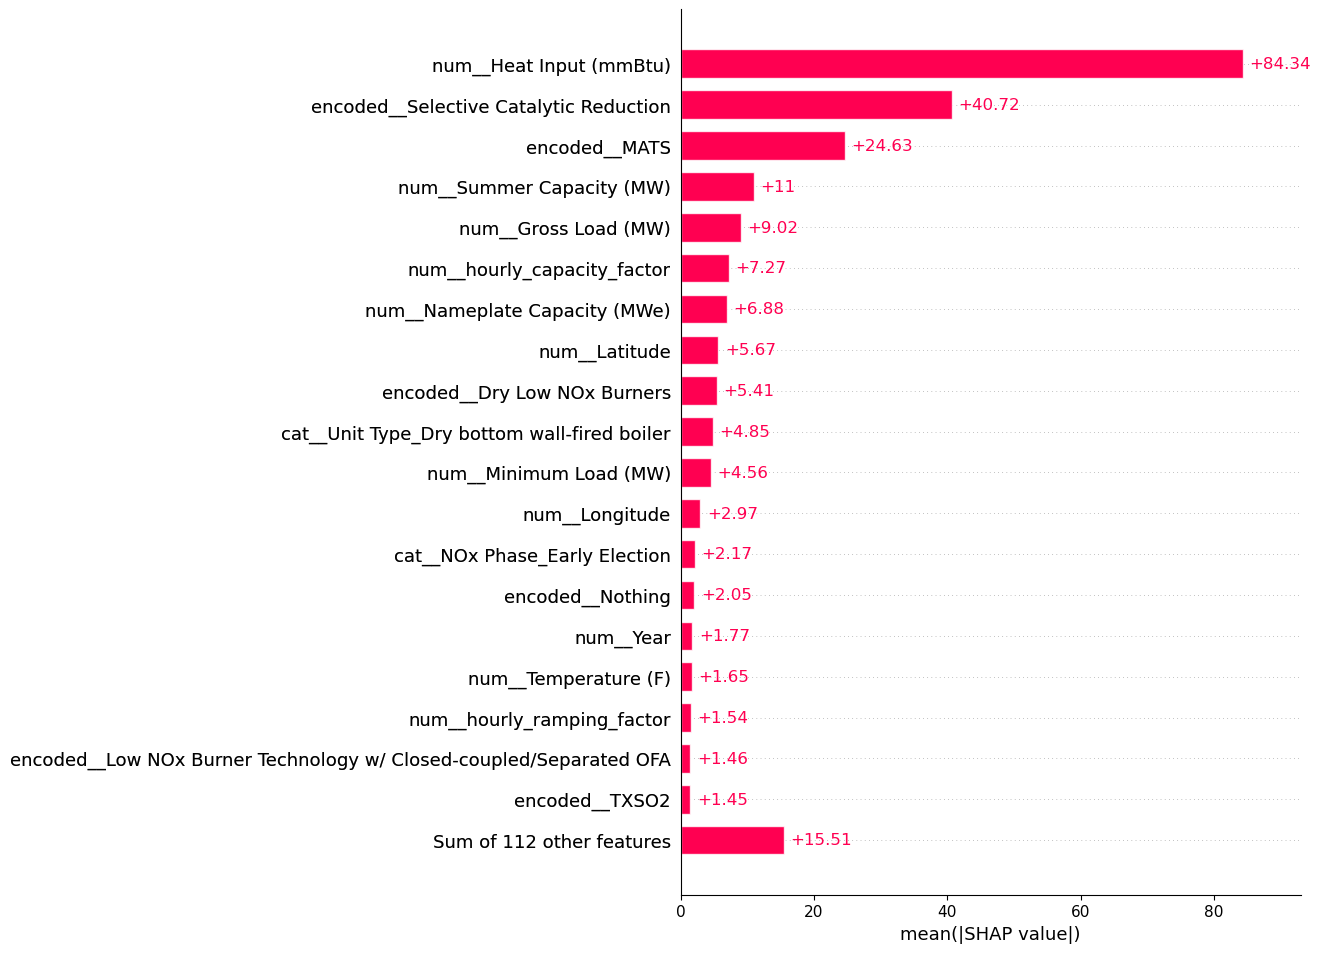

In [13]:
shap.plots.bar(shap_values, max_display=20) # global mean absolute shap values for comparison

In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

In [ ]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


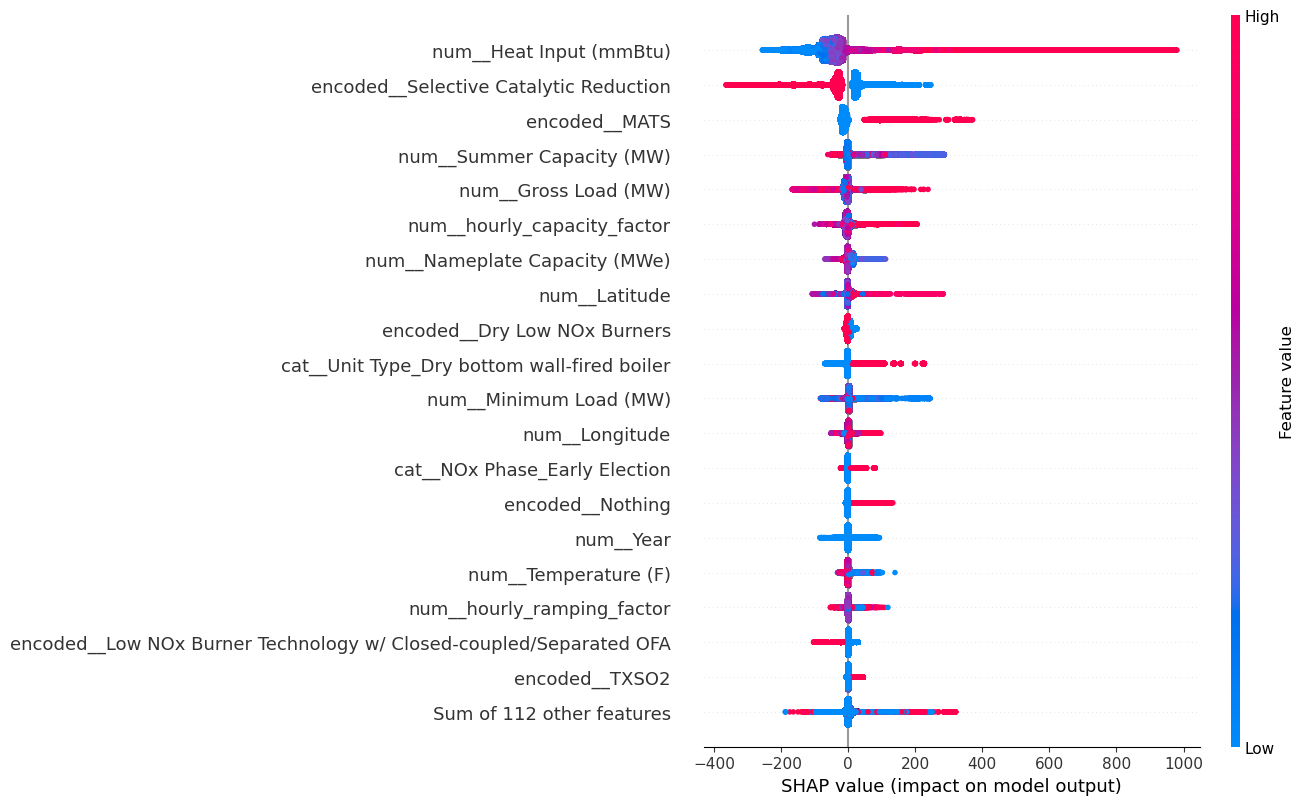

In [14]:
shap.plots.beeswarm(shap_values, max_display=20)


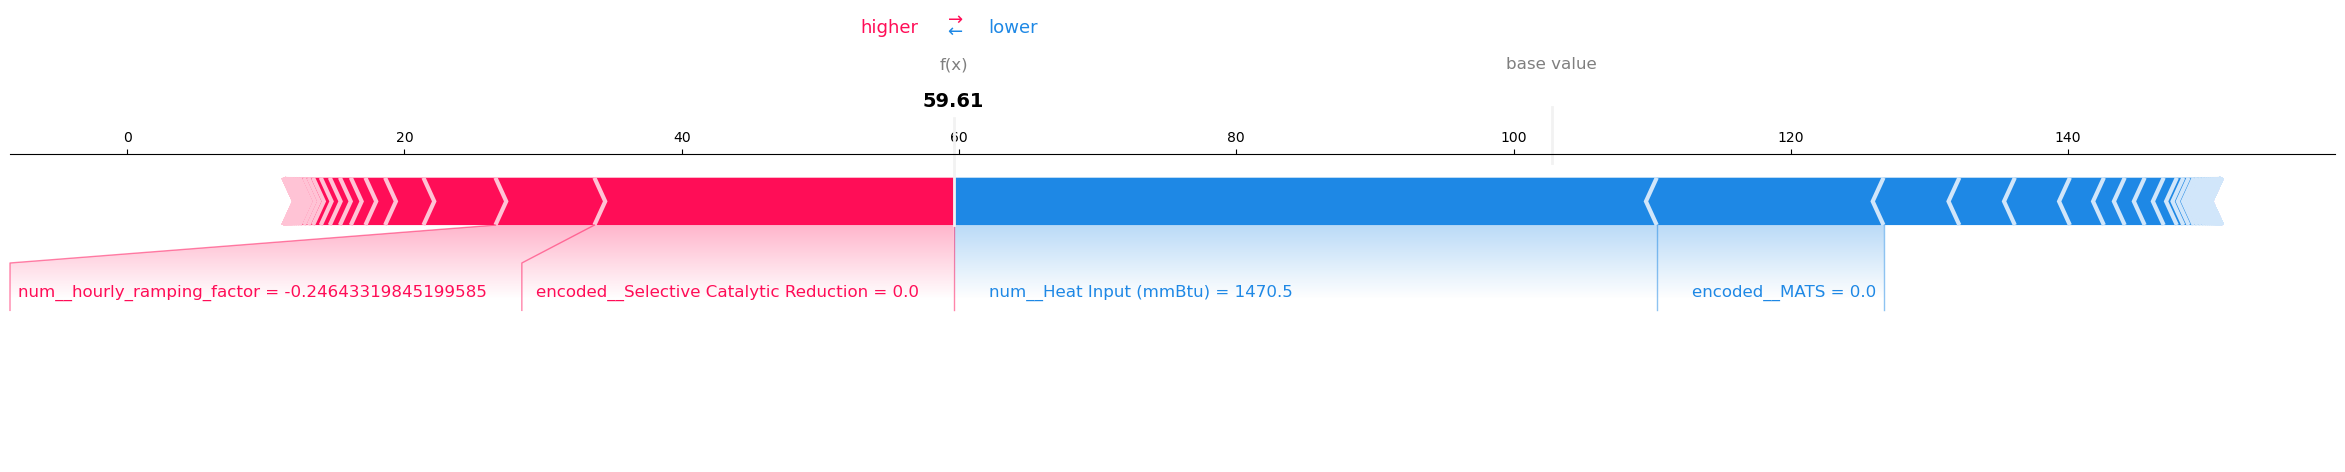

In [15]:
shap.plots.force(explainer(X_test.iloc[[48384]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

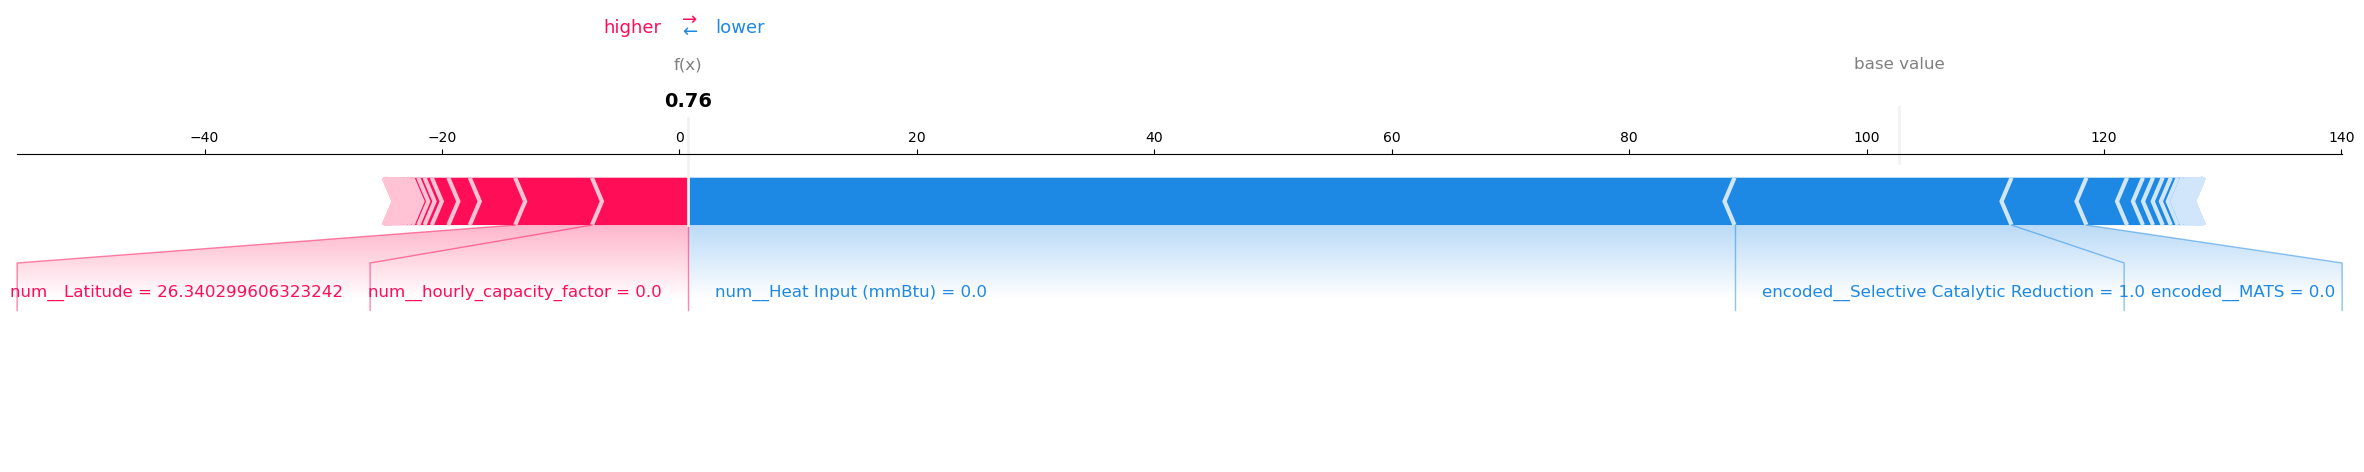

In [16]:
shap.plots.force(explainer(X_test.iloc[[482884]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))


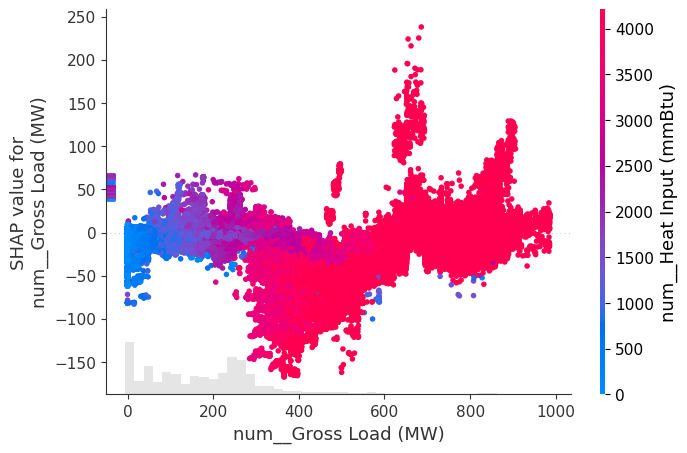

In [17]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

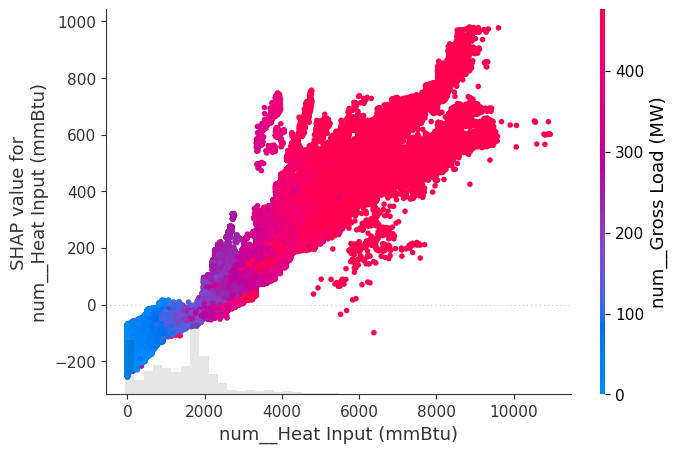

In [18]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

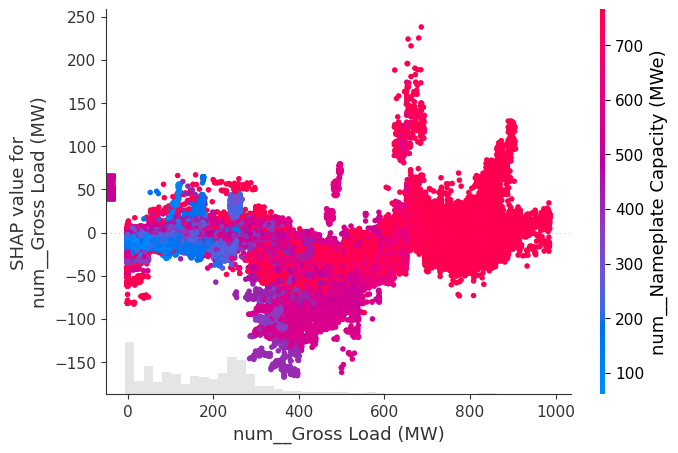

In [19]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

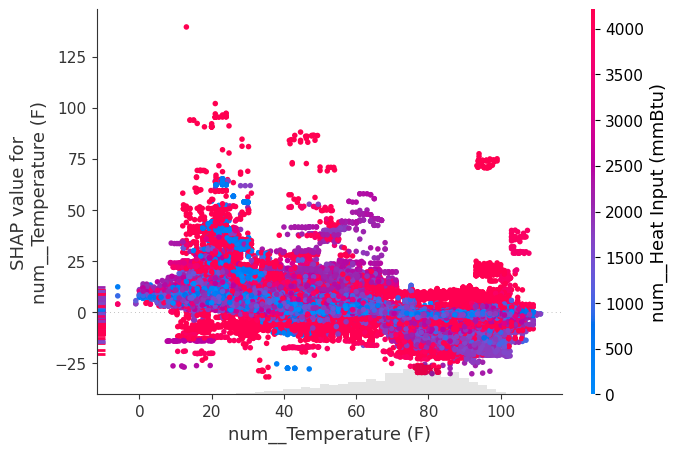

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

# Texas is a very hot state -> we do not observe the same effect as in WY and NY

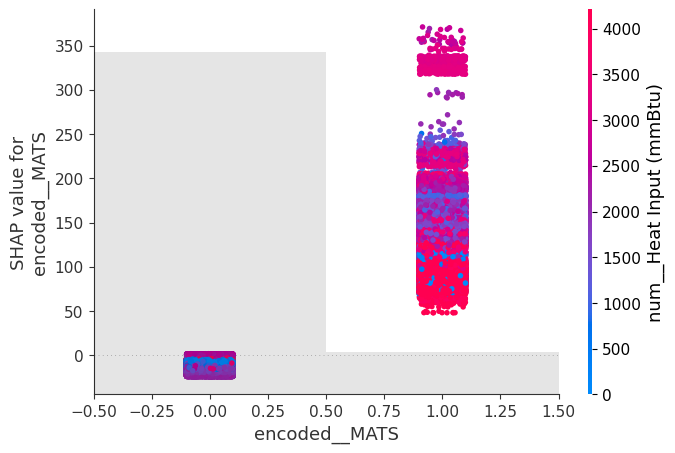

In [ ]:
shap.plots.scatter(shap_values[:, "encoded__MATS"], color=shap_values[:, "num__Heat Input (mmBtu)"])

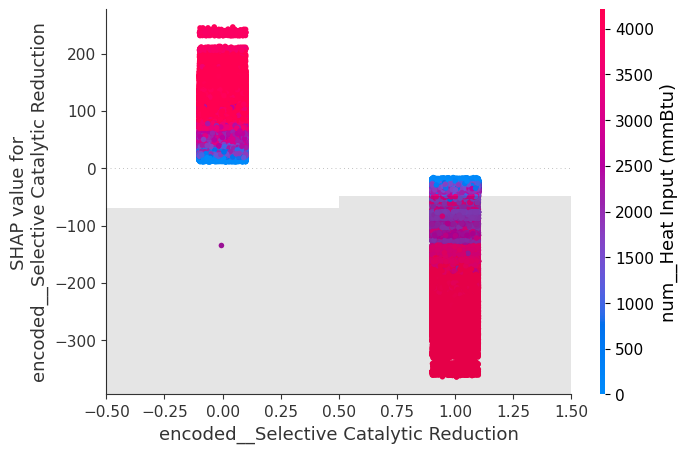

In [ ]:
# interaction between SCR and Heat Input is straightforward
# If SCR is present and heat input is high, then effect towards emissions is highly negative (negative SHAP value)
# If SCR is not present and heat input is high, then effect towards emissions is extremely large 

shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>SHAP Interaction Values</h5>

In [ ]:
X_test_sample = X_test.sample(n=100000, random_state=42)

interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 70 mins

In [24]:
joblib.dump(interaction_values_shap, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl']

In [ ]:
interaction_values_shap = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

In [ ]:
# first we explore how consistent the SI are with SV

In [25]:
interaction_values_shap.shape

(100000, 131, 131)

In [26]:
interaction_values_shap[0].sum()

# interaction_values_shap[i][j][j] gives the main effect of feature j for sample i
# interaction_values_shap[i][j][k] gives the interaction effect of feature j and k for sample i (this is symmetric)

-101.758125

In [32]:
shap_values.feature_names[96]

'num__Heat Input (mmBtu)'

In [34]:
# compare global absolute mean shap values for Heat Input to ensure consistency

print(np.abs(interaction_values_shap[:, 96, :].sum(axis=1)).mean()) # here we first manually compute shap values by iterating over all samples, looking at the interaction array for feature 97 (HI) and sum them to compute the shap value. Then we take the mean absolute val (do axis=1 to sum over each sample (each "row"))
print(np.abs(shap_values.values[:, 96]).mean())

84.65065
84.33844


In [35]:
f = 96
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [36]:
# compute total difference in global shap values between the two calculations

global_shap_vals_interact = np.zeros(interaction_values_shap.shape[1])
global_shap_vals_original = np.zeros(interaction_values_shap.shape[1])

# 
for f in range(interaction_values_shap.shape[1]):
    # Sum interaction values for feature f across all interactions (axis=2),
    # then take absolute value and average over samples (axis=0)
    
    global_shap_vals_interact[f] = np.abs(interaction_values_shap[:, f, :].sum(axis=1)).mean()


    # Mean absolute shap value for feature f from original shap values
    global_shap_vals_original[f] = np.abs(shap_values.values[:, f]).mean()

In [37]:
print(np.abs(main_effects + interactions).mean()) # should be equal to the mean absolute shap value for feature f

84.65065


In [38]:
global_shap_vals_interact[96]

84.65065002441406

In [39]:
global_shap_vals_original[96]

84.33843994140625

Mean absolute difference: 0.009382
Max absolute difference: 0.312210
Min absolute difference: 0.000000


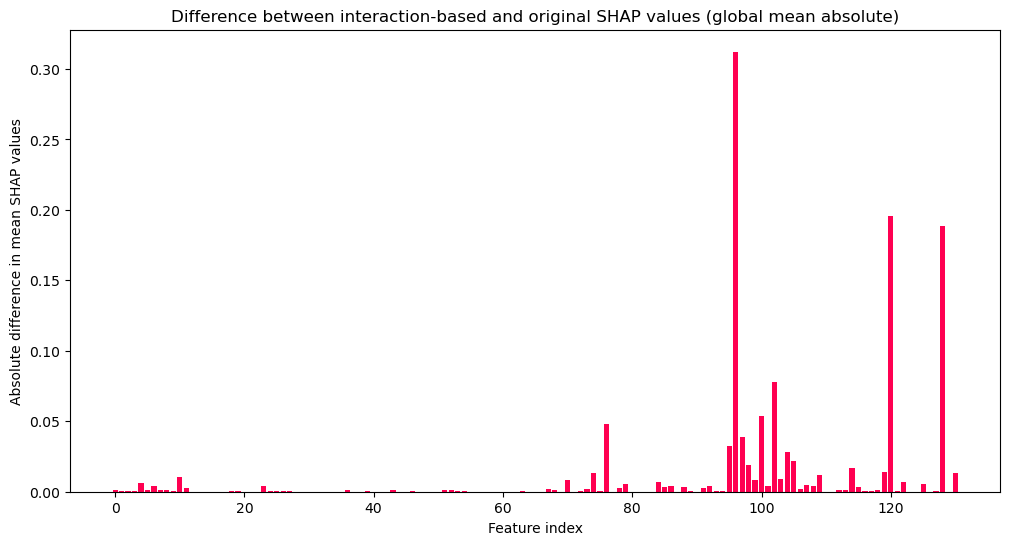

In [40]:
# Compute the absolute differences between the two sets
differences = np.abs(global_shap_vals_interact - global_shap_vals_original)

# Summary stats
print(f"Mean absolute difference: {differences.mean():.6f}")
print(f"Max absolute difference: {differences.max():.6f}")
print(f"Min absolute difference: {differences.min():.6f}")

plt.figure(figsize=(12, 6))
plt.bar(range(len(differences)), differences, color='#FF0051')
plt.xlabel('Feature index')
plt.ylabel('Absolute difference in mean SHAP values')
plt.title('Difference between interaction-based and original SHAP values (global mean absolute)')
plt.show()

# very small differences, maximum is 0.05

In [41]:
feature_names = shap_values.feature_names

n_samples, n_features, _ = interaction_values_shap.shape

# Mean interaction values for each feature pair (averaged over samples)
signed_mean_interactions = interaction_values_shap.mean(axis=0)  # shape (n_features, n_features)
abs_mean_interactions = np.abs(interaction_values_shap).mean(axis=0)

# Flatten to 1D arrays for sorting (before it was shape (n_features, n_features))
flat_mean_abs = abs_mean_interactions.flatten()
flat_mean_signed = signed_mean_interactions.flatten()
# it becomes a 1D array of shape (n_features^2)

# Indices to map back to (feature1, feature2)
idxs = np.array([(i, j) for i in range(n_features) for j in range(n_features)])
# creates an array of tuples (i, j) for each feature pair (each index) with length n_features^2
# we use it to map feature names back later

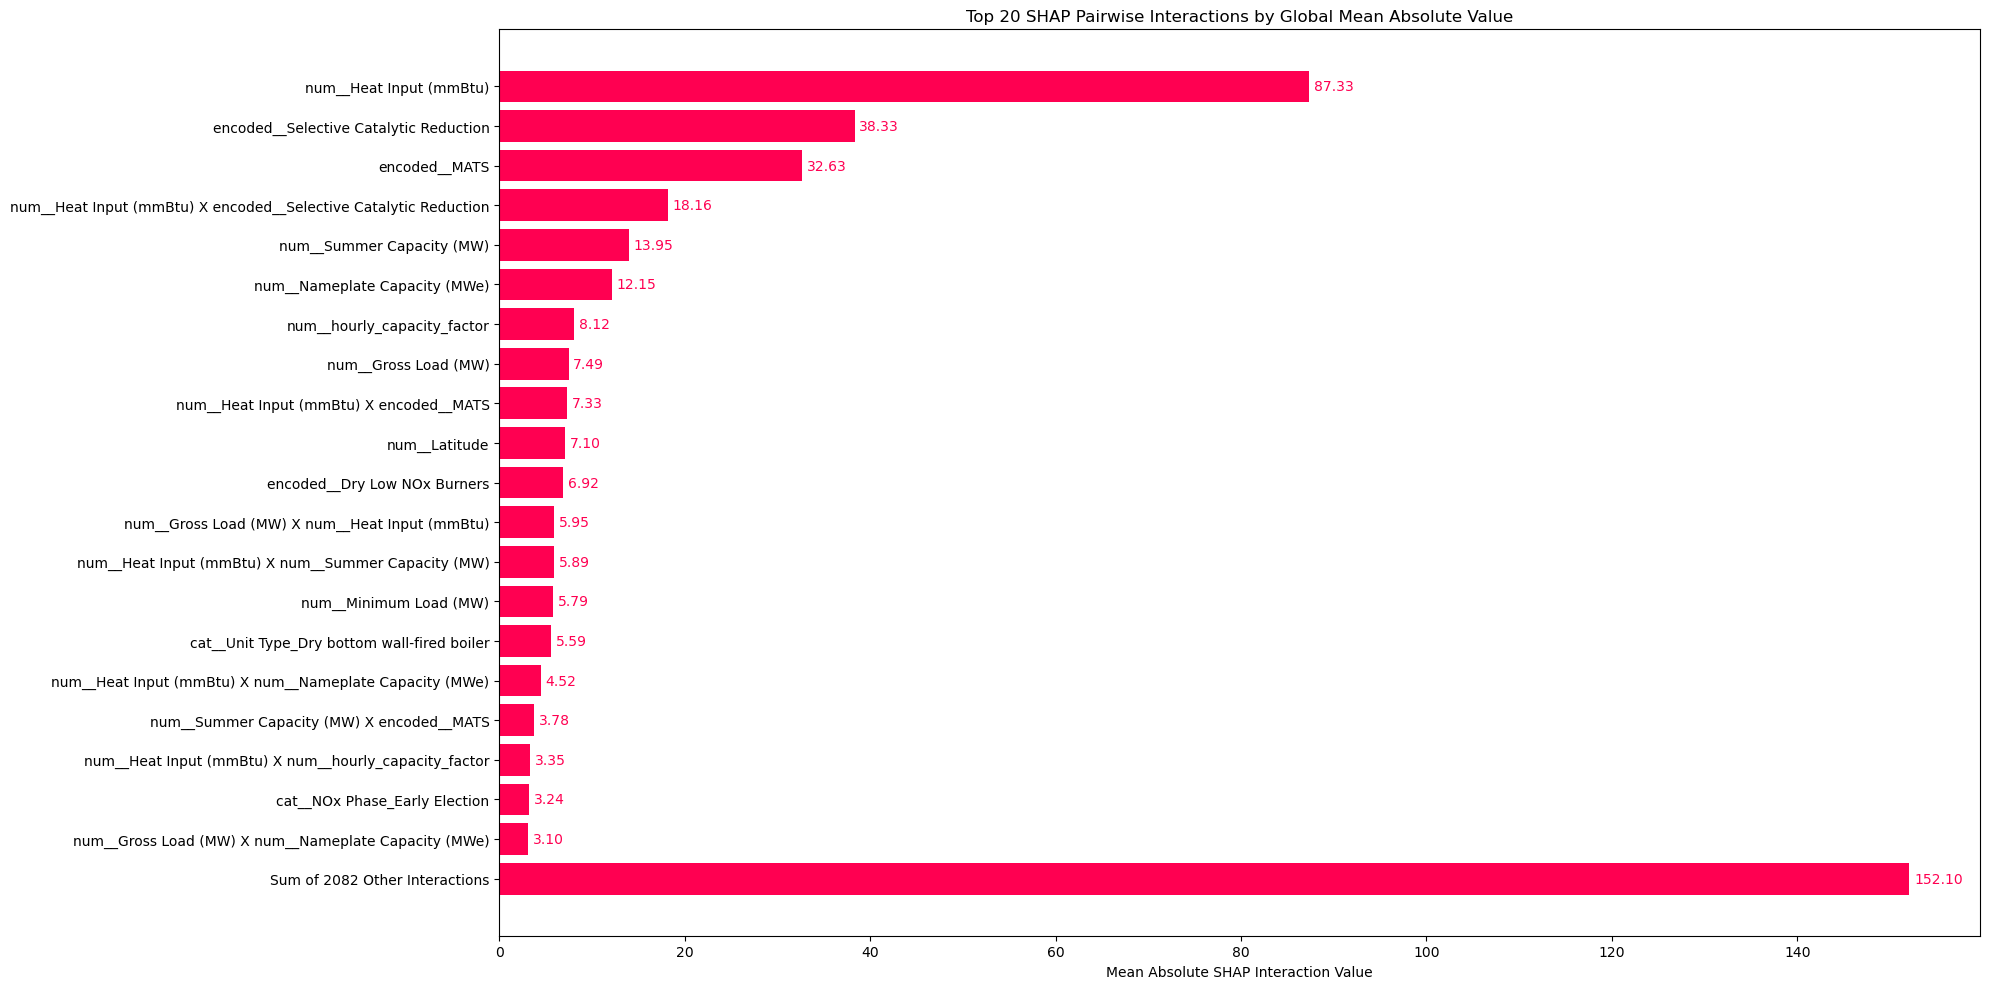

In [42]:
# Top 20 Mean Absolute SHAP Interactions

# Indices to map back to (feature1, feature2), filtering symmetric duplicates
idxs = np.array([(i, j) for i in range(n_features) for j in range(i, n_features)])
# Now idxs only contains pairs where i <= j to avoid duplicates

# Updated flat_mean_abs and flat_mean_signed to account for symmetry reduction
flat_mean_abs = abs_mean_interactions[np.triu_indices(n_features)].flatten()
flat_mean_signed = signed_mean_interactions[np.triu_indices(n_features)].flatten()
# Using np.triu_indices ensures only upper-triangular values are considered (i <= j)

# Filter out zero values by masking them before sorting
nonzero_mask = flat_mean_abs > 0
nonzero_indices = np.where(nonzero_mask)[0]
nonzero_values = flat_mean_abs[nonzero_mask]

# Get top 20 indices (in descending order) from non-zero interactions only
top20_abs_idx_nonzero = nonzero_indices[np.argsort(nonzero_values)[-20:][::-1]]
top20_abs_set = set(top20_abs_idx_nonzero)

# Values and labels for top 20 non-zero interactions
top20_abs = [((feature_names[i], feature_names[j]), flat_mean_abs[idx]) 
             for idx, (i, j) in zip(top20_abs_idx_nonzero, idxs[top20_abs_idx_nonzero])]
labels_abs = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_abs]
raw_values_abs = [v for _, v in top20_abs]

# Sum of others excluding top 20 and zero interactions
all_nonzero_indices = set(nonzero_indices)
other_abs_idx = list(all_nonzero_indices - top20_abs_set)
sum_other_abs = flat_mean_abs[other_abs_idx].sum()

# Append summary
labels_abs.append(f"Sum of {len(other_abs_idx)} Other Interactions")
raw_values_abs.append(sum_other_abs)

# All absolute values, one color
bar_colors_abs = ['#FF0051'] * len(labels_abs)

# Plot Absolute Interactions
plt.figure(figsize=(20, 10))
bars_abs = plt.barh(range(len(labels_abs)), raw_values_abs, color=bar_colors_abs)
plt.yticks(range(len(labels_abs)), labels_abs)
plt.xlabel("Mean Absolute SHAP Interaction Value")
plt.title("Top 20 SHAP Pairwise Interactions by Global Mean Absolute Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_abs, raw_values_abs):
    plt.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

In [ ]:
# mostly relates to Mercury
print(f"MATS-Units make up {round(y_test[X_test[X_test["encoded__MATS"] == 1].index].sum() / y_test.sum() * 100, 2)} % of total emissions in X_test")
print(f"With an average emission of {round(y_test[X_test[X_test["encoded__MATS"] == 1].index].mean()*1, 2)}")

print(f"\nARP-Units make up {round(y_test[X_test[X_test['encoded__ARP'] == 1].index].sum() / y_test.sum() * 100, 2)} % of total emissions in X_test")
print(f"With an average emission of {round(y_test[X_test[X_test['encoded__ARP'] == 1].index].mean(), 2)}")

print(f"\nCSOSG2-Units make up {round(y_test[X_test[X_test['encoded__CSOSG2'] == 1].index].sum() / y_test.sum() * 100, 2)} % of total emissions in X_test")
print(f"With an average emission of {round(y_test[X_test[X_test['encoded__CSOSG2'] == 1].index].mean(), 2)}")

# only regulates SO2
print(f"\nTXSO2-Units make up {round(y_test[X_test[X_test['encoded__TXSO2'] == 1].index].sum() / y_test.sum() * 100, 2)} % of total emissions in X_test")
print(f"With an average emission of {round(y_test[X_test[X_test['encoded__TXSO2'] == 1].index].mean(), 2)}")

# hypothesis why MATS has such a high SHAP value but not TXSO2: XGB chooses one of either, they are somewhat redundant so it selects MATS because it has more value

MATS-Units make up 54.23 % of total emissions in X_test
With an average emission of 460.99

ARP-Units make up 100.0 % of total emissions in X_test
With an average emission of 95.62999725341797

CSOSG2-Units make up 100.0 % of total emissions in X_test
With an average emission of 93.6500015258789

TXSO2-Units make up 45.98 % of total emissions in X_test
With an average emission of 450.1600036621094


In [73]:
campd_df[campd_df["Program Code"].isin(["ARP, CSOSG2, MATS, TXSO2", "ARP, CSOSG2, MATS"])][["Unit Type", "Primary Fuel Type"]].value_counts()

Unit Type                         Primary Fuel Type
Tangentially-fired                Coal                 797265
Dry bottom wall-fired boiler      Coal                 331616
Circulating fluidized bed boiler  Coal                  98106
Name: count, dtype: int64

In [72]:
campd_df[campd_df["Program Code"].isin(["ARP, CSOSG2, MATS, TXSO2", "ARP, CSOSG2, TXSO2"])][["Unit Type", "Primary Fuel Type"]].value_counts()

Unit Type                     Primary Fuel Type   
Tangentially-fired            Coal                    582814
Dry bottom wall-fired boiler  Coal                    190623
                              Pipeline Natural Gas    121392
Tangentially-fired            Pipeline Natural Gas    118435
Combined cycle                Pipeline Natural Gas     77958
Name: count, dtype: int64

In [77]:
campd_df[(campd_df["Year"] == 2024) & (campd_df["Program Code"].isin(["ARP, CSOSG2, MATS, TXSO2", "ARP, CSOSG2, MATS"]))]["NOx Mass (lbs)"].describe()

count    189486.000000
mean        460.993073
std         309.721130
min           0.000000
25%         235.699997
50%         418.500000
75%         599.799988
max        2490.199951
Name: NOx Mass (lbs), dtype: float64

In [78]:
campd_df[(campd_df["Year"] == 2024) & (campd_df["Program Code"].isin(["ARP, CSOSG2, MATS, TXSO2", "ARP, CSOSG2, TXSO2"]))]["NOx Mass (lbs)"].describe()

count    164516.000000
mean        450.162506
std         398.922424
min           0.000000
25%         141.899994
50%         390.600006
75%         635.400024
max        3316.500000
Name: NOx Mass (lbs), dtype: float64

In [ ]:
# for those units with TXSO2, but not MATS, the mean NOx is much lower -> supports the hypothesis
campd_df[(campd_df["Year"] == 2024) & (campd_df["Program Code"] == "ARP, CSOSG2, TXSO2")]["NOx Mass (lbs)"].describe()

count    48873.000000
mean       291.999176
std        463.153839
min          0.000000
25%         77.800003
50%        131.899994
75%        228.600006
max       3316.500000
Name: NOx Mass (lbs), dtype: float64

In [55]:
campd_df["Program Code"].value_counts()

Program Code
ARP, CSOSG2                 7994519
ARP, CSOSG2, MATS, TXSO2     773437
ARP, CSOSG2, MATS            453550
ARP, CSOSG2, TXSO2           317785
CSOSG2                       212041
ARP                            6498
Missing                         876
Name: count, dtype: Int64

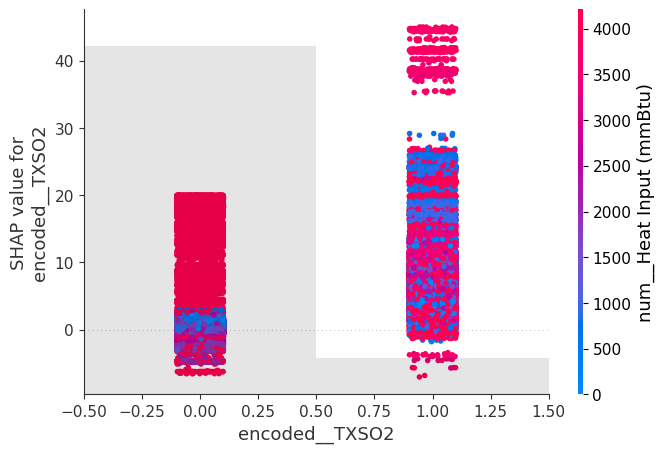

In [ ]:
shap.plots.scatter(shap_values[:, "encoded__TXSO2"], color=shap_values[:, "num__Heat Input (mmBtu)"])

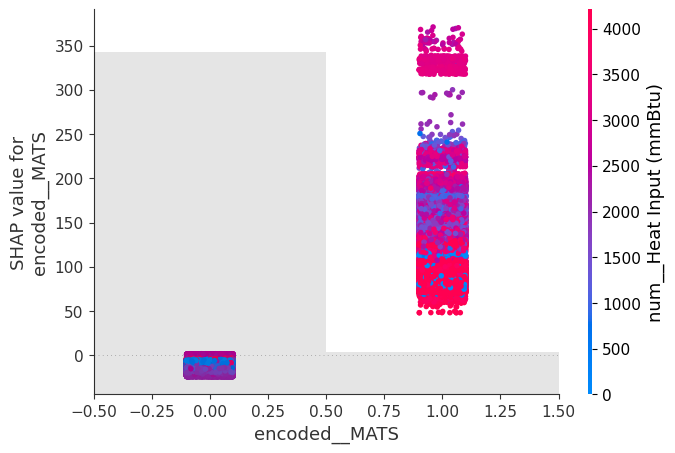

In [53]:
shap.plots.scatter(shap_values[:, "encoded__MATS"], color=shap_values[:, "num__Heat Input (mmBtu)"])

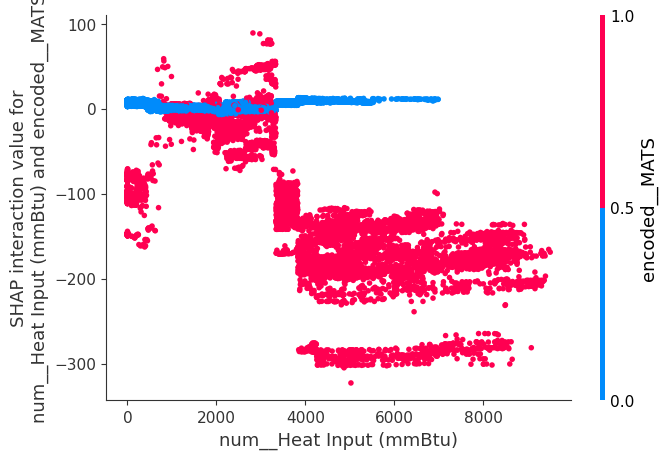

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__MATS"), interaction_values_shap, X_test_sample, show=True)

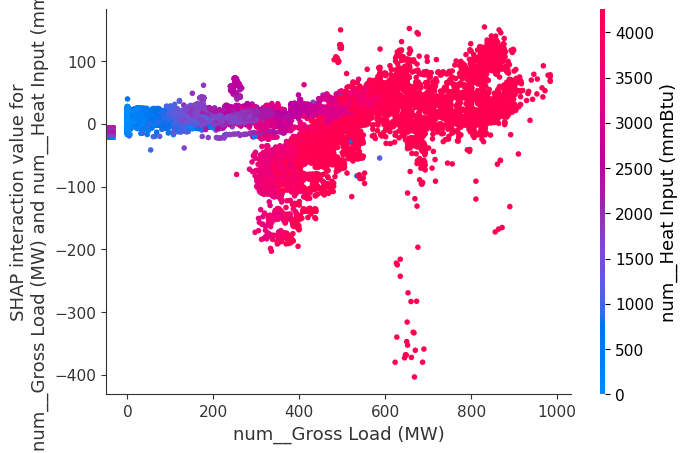

In [43]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Heat Input (mmBtu)"), interaction_values_shap, X_test_sample, show=True)

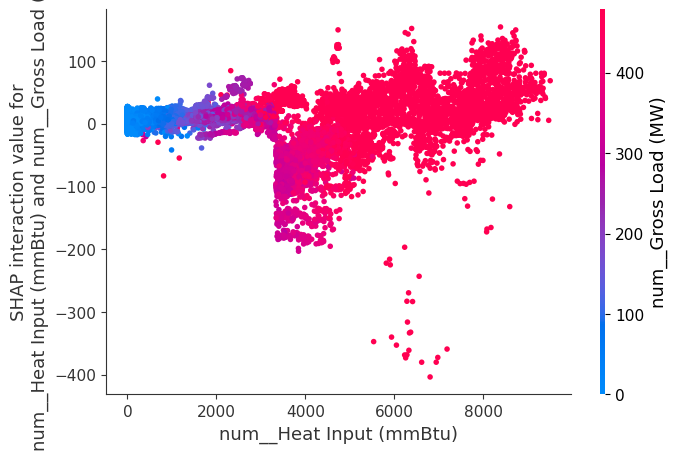

In [44]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "num__Gross Load (MW)"), interaction_values_shap, X_test_sample, show=True)

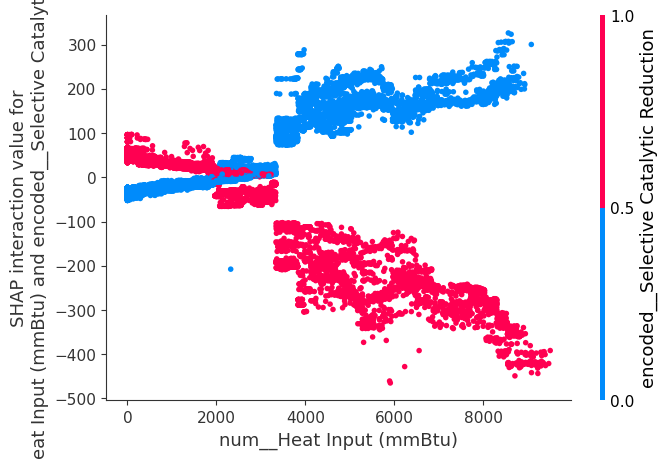

In [45]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Selective Catalytic Reduction"), interaction_values_shap, X_test_sample, show=True)

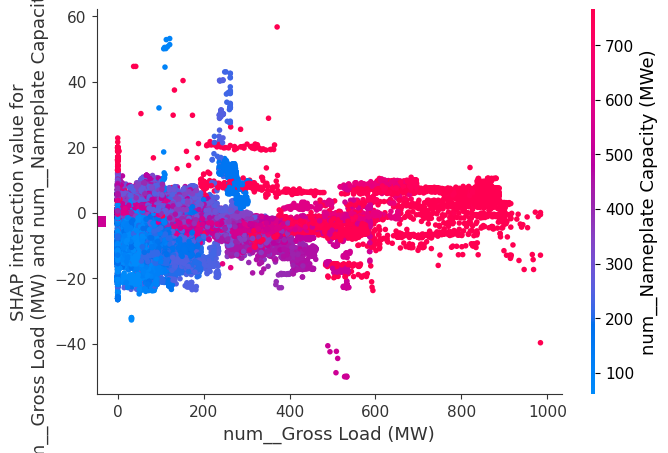

In [46]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Nameplate Capacity (MWe)"), interaction_values_shap, X_test_sample, show=True)

<h4>shapiq</h4>

In [10]:
import shapiq

In [11]:
default_params

{'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'seed': 42}

In [12]:
from xgboost import XGBRegressor

# create an XGBRegressor because shapiq doesn't work with booster objects
model = XGBRegressor(**default_params)
model.fit(X_train, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [ ]:
explainer_shapiq = shapiq.TreeExplainer(model=model, max_order=2)

In [ ]:
X_test_sample_array = X_test.sample(n=100000, random_state=42).to_numpy()
interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, index="SII", n_jobs=-1)
# specify to use "SII" instead "k-SII" -> we only want pairwise interactions like in normal SHAP package
# this ran for 2 hours without finishing


In [16]:
X_test_sample_array = X_test.sample(n=100, random_state=42).to_numpy()

interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, n_jobs=-1)

# this took XY mins
# WRITE DOWN HOW LONG IT TOOK
# LOOK AT DEPENDENCE PLOT AT THE TOP FOR TOP INTERACTIONS AND DIRECTIONALITY
# HOW DO SHAPIQ INTERACTIONS COMPARE TO SHAP INTERACTIONS? DIFFERENT ALGORITHMS?
# E. G. INTERACTION HEAT INPUT AND GROSS LOAD

In [14]:
X_test_sample_array = X_test.sample(n=100, random_state=42).to_numpy()

interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, index="SII", n_jobs=-1)

# this took XY mins
# WRITE DOWN HOW LONG IT TOOK
# LOOK AT DEPENDENCE PLOT AT THE TOP FOR TOP INTERACTIONS AND DIRECTIONALITY
# HOW DO SHAPIQ INTERACTIONS COMPARE TO SHAP INTERACTIONS? DIFFERENT ALGORITHMS?
# E. G. INTERACTION HEAT INPUT AND GROSS LOAD

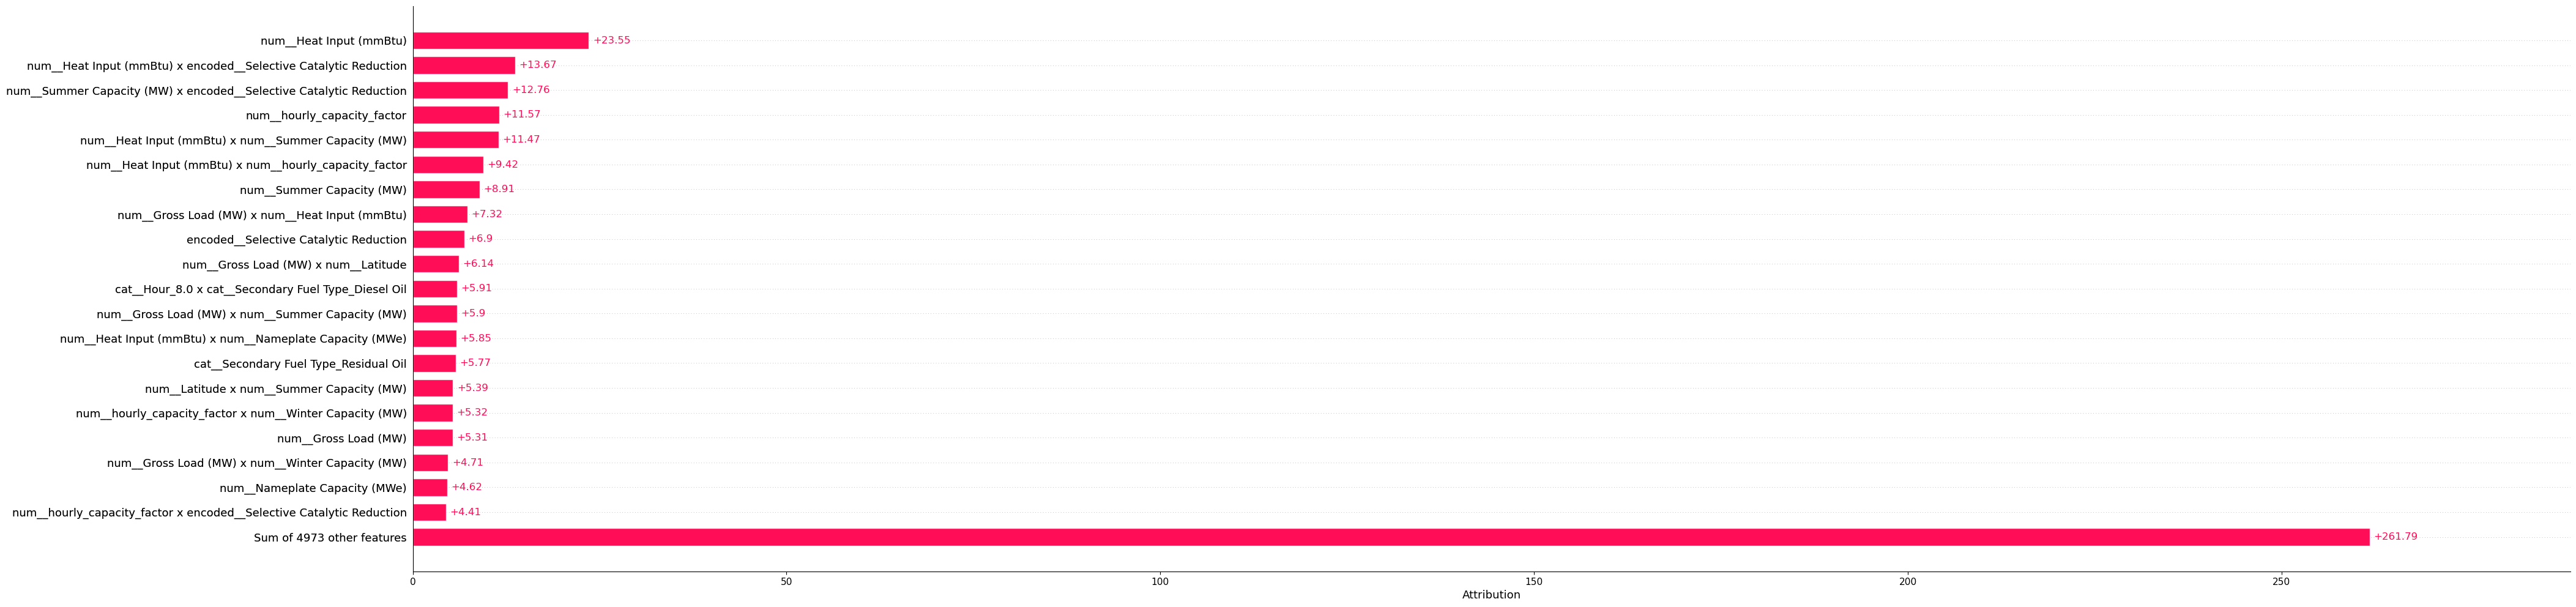

In [15]:
shapiq.plot.bar_plot(interaction_values_shapiq, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

In [19]:
shapiq.plot.waterfall_plot(interaction_values_shapiq, feature_names=X_test.columns, show=True, abbreviate=False)

AttributeError: 'list' object has no attribute 'n_players'

In [ ]:
# ALSO MAYBE TRY PREDICTING NOx FROM ANOTHER RGGI STATE USING THE TX MODEL TO SHOW LIMITED TRANSFERABILITY

In [ ]:
joblib.dump(interaction_values_shapiq, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shapiq_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

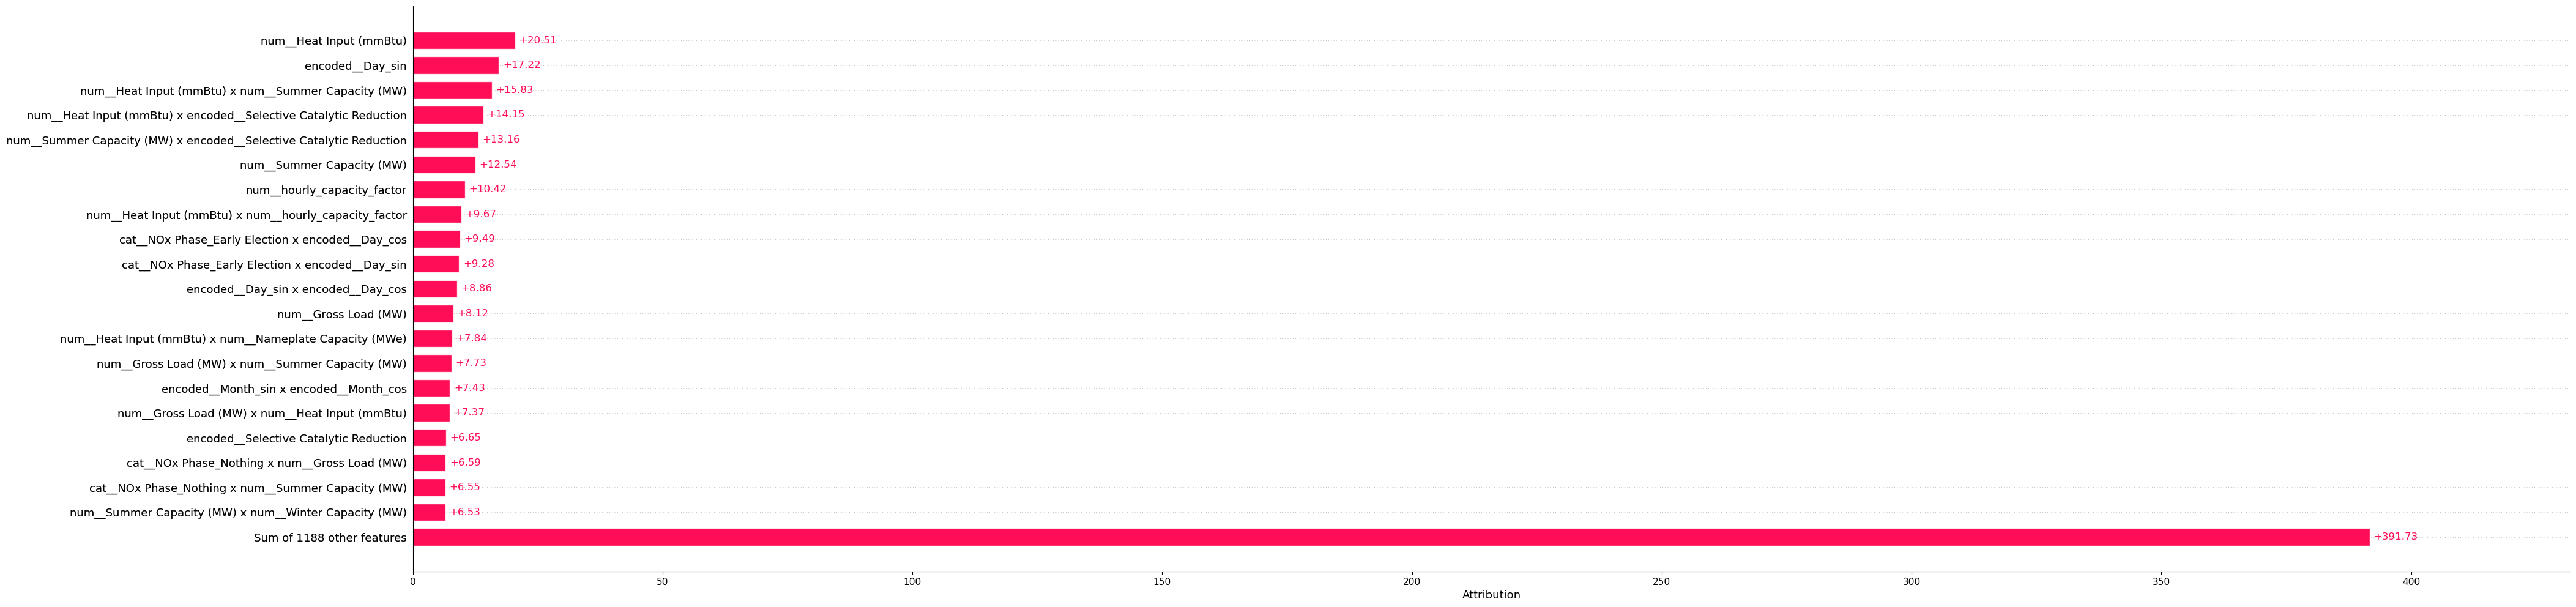

In [ ]:
shapiq.plot.bar_plot(list_of_interaction_values, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

In [304]:
interaction_values = explainer_shapiq.explain(X_test.iloc[2000])
print(interaction_values)

c:\Users\marce\anaconda3\Lib\site-packages\shapiq\explainer\tree\treeshapiq.py:180: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x_relevant = x[self._relevant_features]
c:\Users\marce\anaconda3\Lib\site-packages\shapiq\explainer\tree\treeshapiq.py:320: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if x[child_edge_feature] <= feature_threshold:


InteractionValues(
    index=k-SII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=73, baseline_value=21.24664253362357,
    Top 10 interactions:
        (30, 51): 61.865503774544855
        (30, 36): 41.76005722528839
        (69,): 36.610711633194704
        (36, 51): 31.057869709942327
        (3, 70): 22.735285441776984
        (29,): 21.406142721995078
        (): 21.24664253362357
        (34, 36): 20.917203006279173
        (3, 69): -20.838209959600213
        (30, 31): -26.451239804108916
)


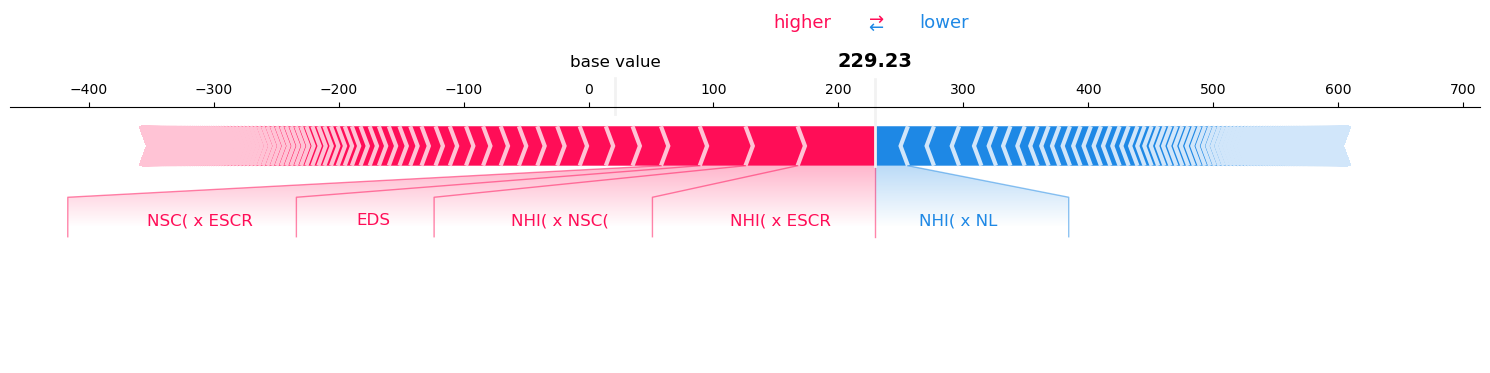

In [253]:
interaction_values.plot_force(feature_names=X_test.columns, abbreviate=True, contribution_threshold=0.03)

In [ ]:
X_test_sample = X_test.sample(n=2000, random_state=42)
X_test_array = X_test_sample.to_numpy()

In [ ]:
X_test_small = X_test_array[:1000]
interaction_values = explainer_shapiq.explain_X(X_test_small, budget=256, n_jobs=-1)


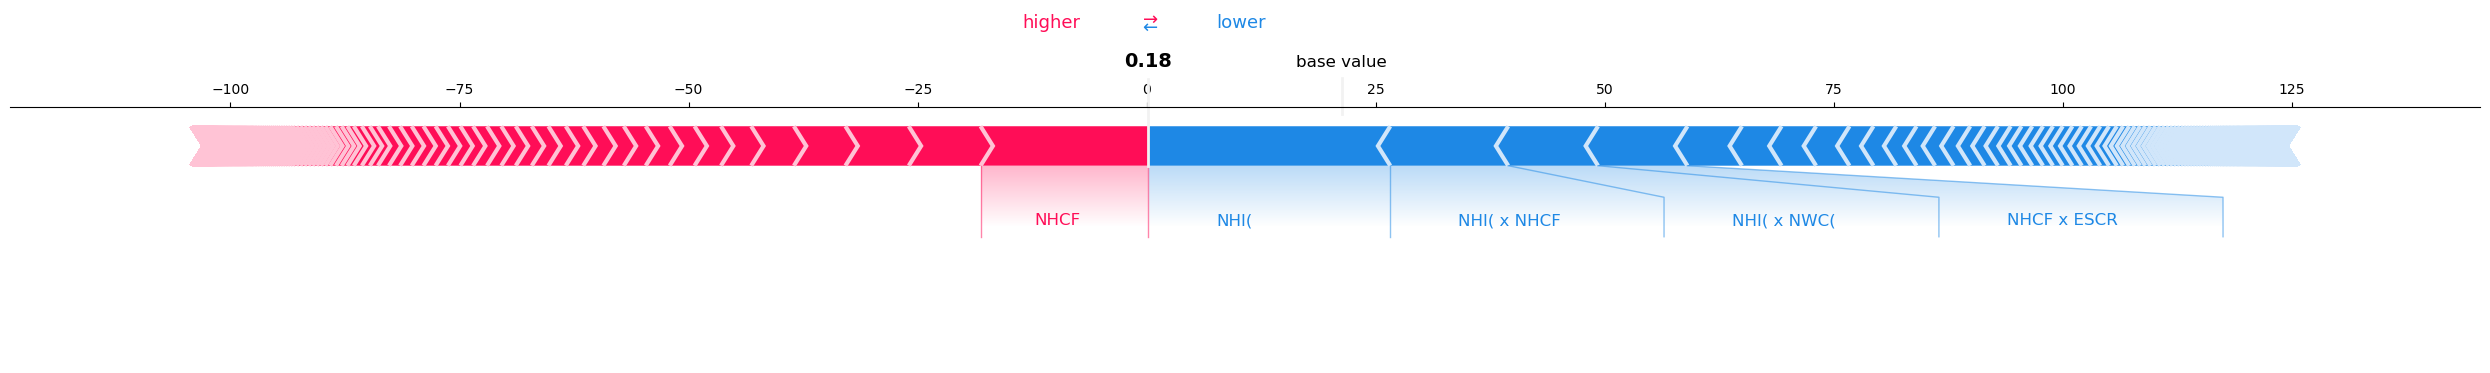

In [286]:
shapiq.plot.force_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=True, figsize=(25,4))

In [289]:
y_pred[0]

0.049161565

In [273]:
explanation.dict_values

{(): 21.24664253362357,
 (3,): 0.010116192353452177,
 (4,): 2.8852820410238187,
 (5,): -0.0018342788388277626,
 (8,): -0.050556700028876696,
 (18,): 2.232573874403288,
 (27,): -5.949784035694675,
 (29,): 6.912368211716091,
 (30,): -26.385748366828764,
 (31,): 0.20066403911291167,
 (33,): -1.0558655633671323,
 (34,): 18.32777062274561,
 (35,): -0.4164808687782936,
 (36,): 2.3963361683612083,
 (37,): 7.833275079031403,
 (48,): -0.03287189180138845,
 (50,): 0.6220878739498158,
 (51,): 5.623920674455167,
 (71,): 1.5570077274585223,
 (72,): 1.385087303814235,
 (3, 4): -0.002900521410567616,
 (3, 5): 0.0,
 (3, 8): 0.0,
 (3, 18): -0.20046050347618039,
 (3, 27): 0.05851231018565594,
 (3, 29): 0.17748192854782077,
 (3, 30): 0.10192031961110799,
 (3, 31): -0.007066022481051599,
 (3, 33): 0.03323761386403886,
 (3, 34): 0.005024052470390323,
 (3, 35): -0.053982396776276725,
 (3, 36): 0.014134244889001009,
 (3, 37): -0.020213351888961745,
 (3, 48): 0.0,
 (3, 50): 0.003043905812738481,
 (3, 51): 0.0

In [ ]:
# Get the feature names and values for the data point
feature_names = list(X_test.columns)
x0 = X_test.iloc[0]

# Replace tuple indices with actual names + values and sort by abs value
sorted_named_values = sorted(
    {
        tuple(f"{feature_names[i]} ({x0[i]})" for i in k): v
        for k, v in interaction_values.dict_values.items()
    }.items(),
    key=lambda x: abs(x[1]),
    reverse=True
)

# Display top 10 interactions
top_10 = sorted_named_values[:10]
for features, value in top_10:
    name = " & ".join(features)
    print(f"{name}: {value:.4f}")


In [52]:

X_test_sample = X_test.sample(n=360)
X_test_array = X_test_sample.to_numpy()
list_of_interaction_values = explainer_shapiq.explain_X(X_test_array, budget=256, n_jobs=-1)
len(list_of_interaction_values)

360

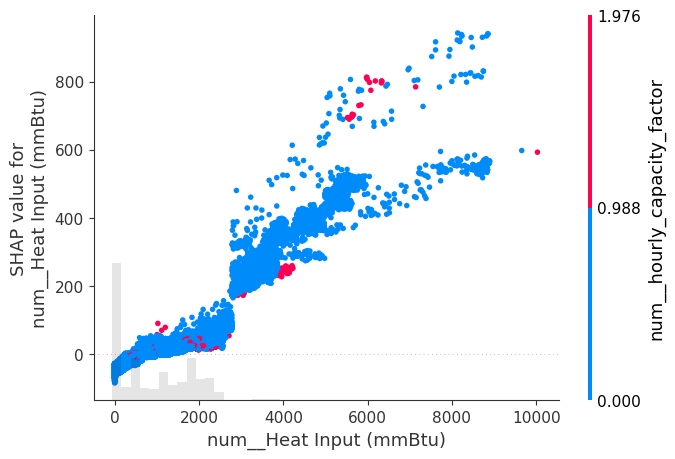

In [241]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__hourly_capacity_factor"])

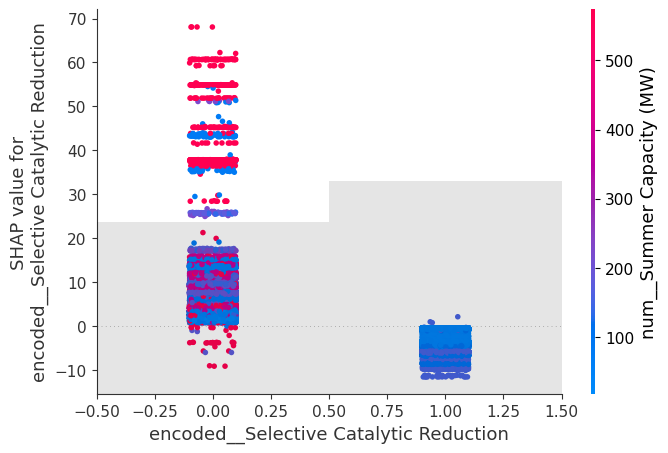

In [237]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Summer Capacity (MW)"])

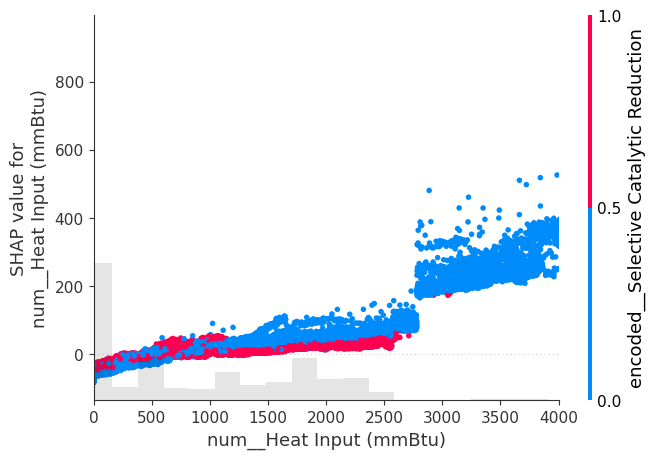

In [235]:
# Create the scatter plot
shap.plots.scatter(shap_values[:, "num__Heat Input (mmBtu)"], 
                   color=shap_values[:, "encoded__Selective Catalytic Reduction"],show=False)

# Adjust the x-axis limits
plt.xlim(0, 4000)  # Replace 'lower_limit' and 'upper_limit' with your desired range

# Show the updated plot
plt.show()

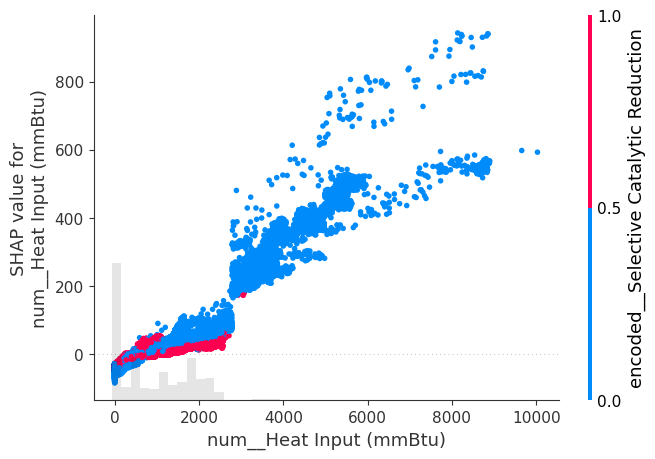

In [232]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])

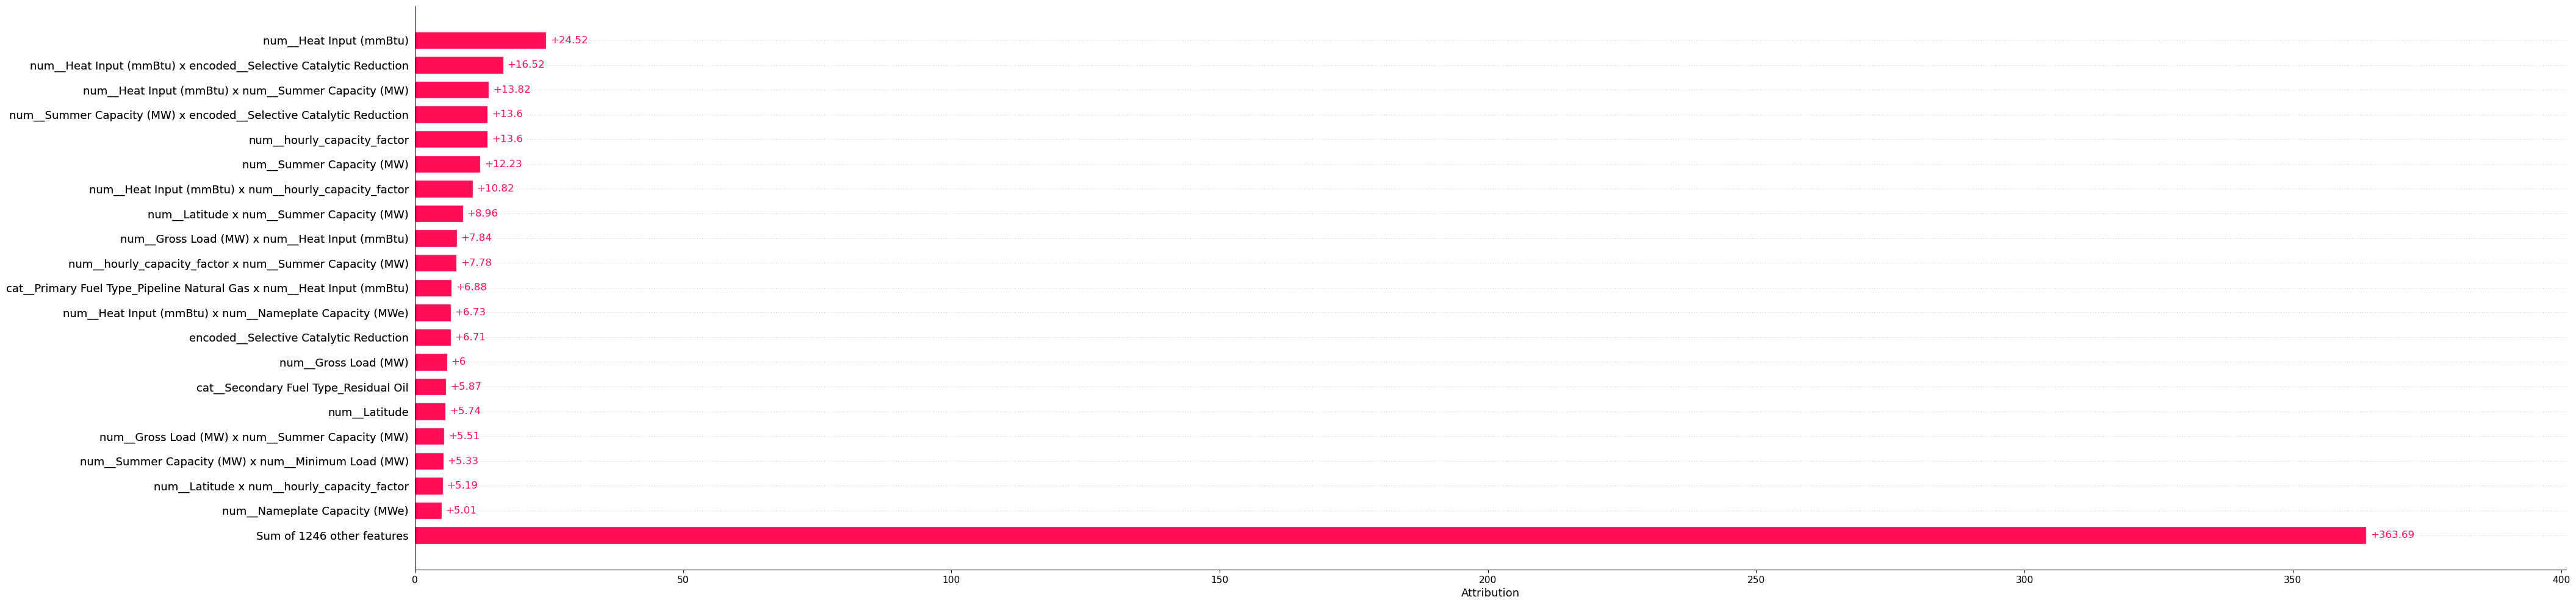

In [53]:
shapiq.plot.bar_plot(list_of_interaction_values, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

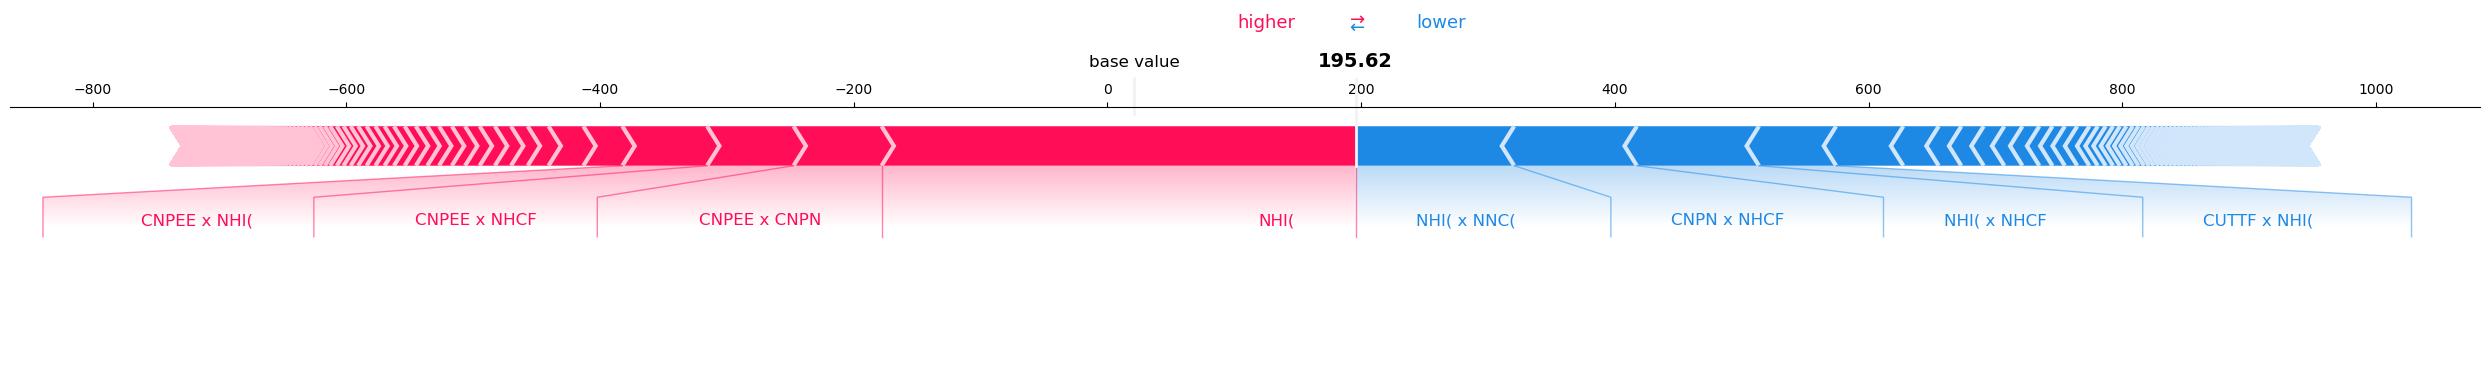

In [107]:
shapiq.plot.force_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=True, figsize=(25,4))

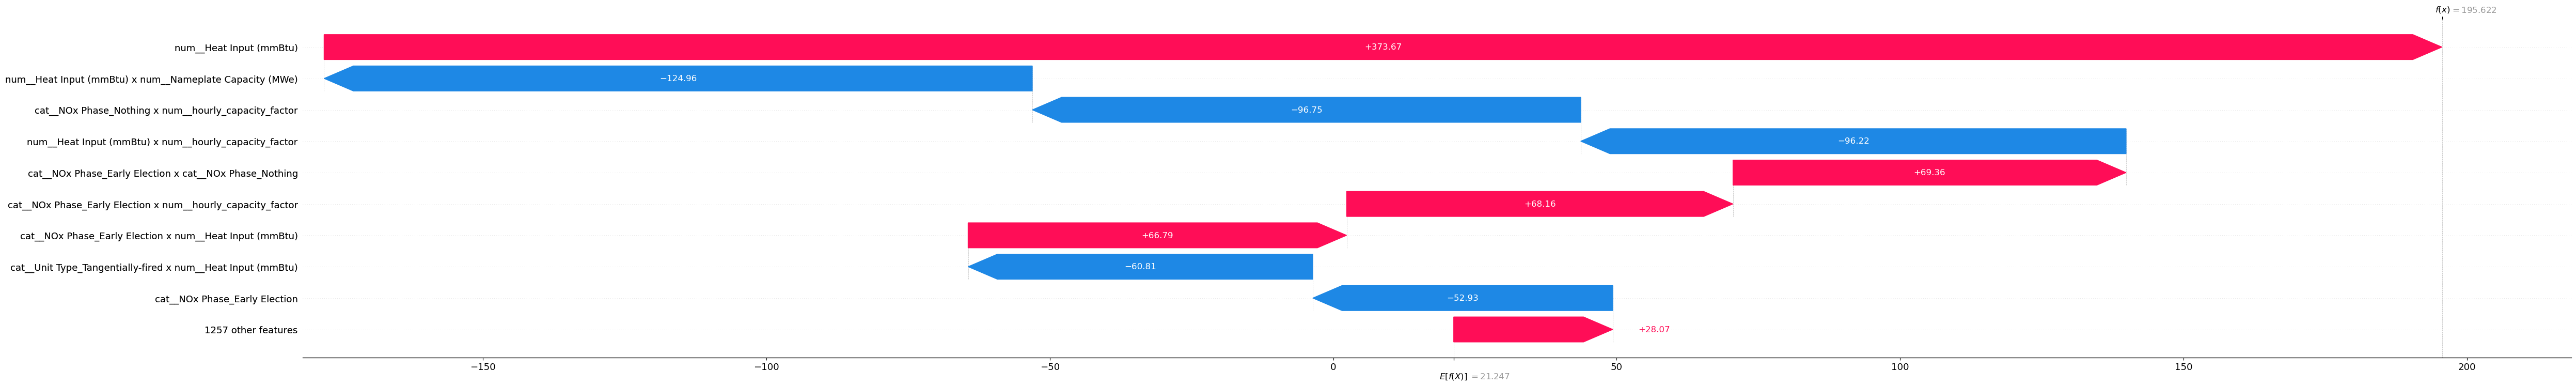

In [98]:
shapiq.plot.waterfall_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=False)

<h5>With Lags, No Temps</h5>

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model)

In [ ]:
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [ ]:
shap_values = explainer(X_test, approximate=False)

In [ ]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_tx_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_tx_with_lags_no_unmeasured.pkl")

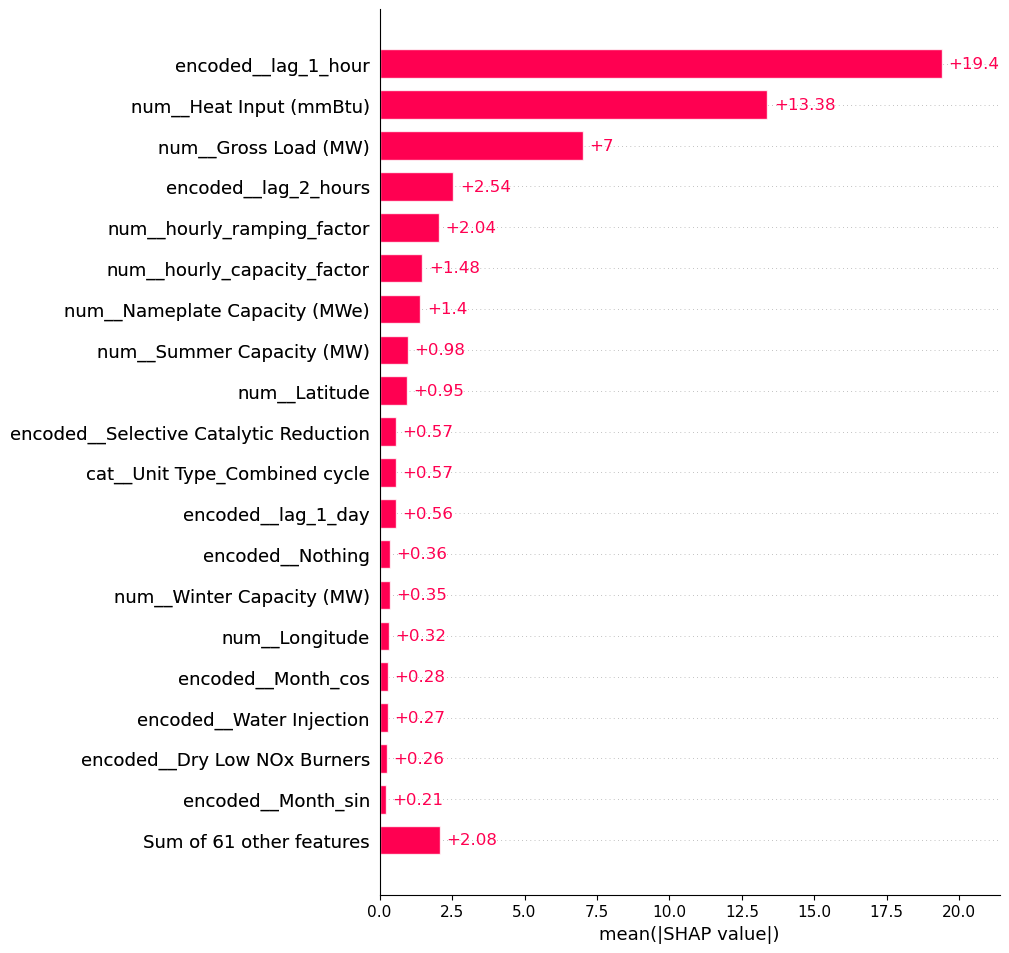

In [ ]:
shap.plots.bar(shap_values, max_display=20)

In [ ]:
shap.plots.waterfall(shap_values[0], max_display=20)

In [ ]:
# global visualizations

# shap.plots.bar(shap_values) # mean absolute value of each feature over all rows
# shap.plots.bar(shap_values.abs.max(0)) # gives max absolute values of features e. g. if features occur infrequently, but have significant effects
# shap.plots.beeswarm(shap_values) # beeswarm plot -> gives context on relationships of high and low feature values to SHAP values

# deal with clustering
# clustering = shap.utils.hclust(X_adult, y_adult)
# shap.plots.bar(shap_values, clustering=clustering)
# shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=1) # sets distance threshold for clusters, lower values will create smaller clusters

# shap.plots.scatter(shap_values, ylabel="SHAP value") # scatter plots between feature and shap values

<h4>Using HPO parameters</h4>

In [4]:
explainer = shap.TreeExplainer(xgb_hpo_model)

In [ ]:
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [6]:
shap_values = explainer(X_test, approximate=True) # need to approximate because otherwise it is to computationally expensive for the hpo model

In [ ]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_tx_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_tx_with_lags_no_unmeasured.pkl")

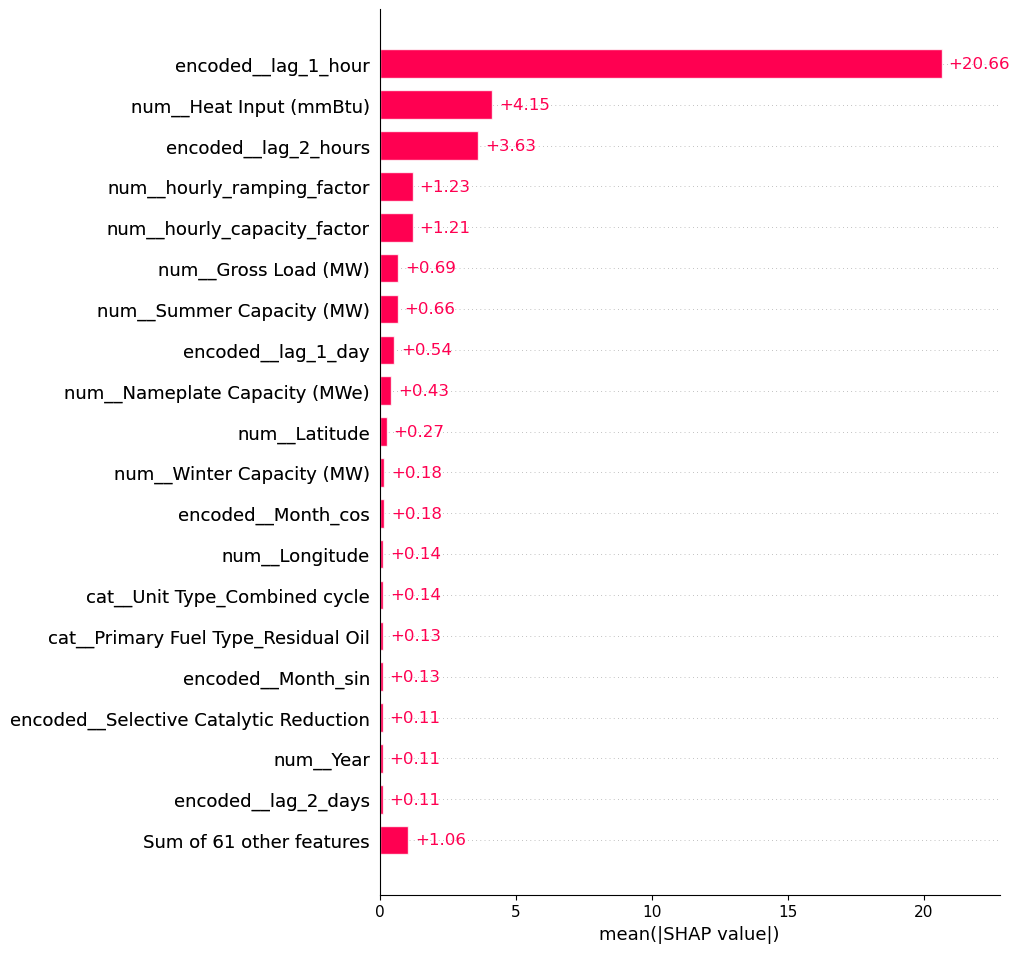

In [8]:
shap.plots.bar(shap_values, max_display=20)

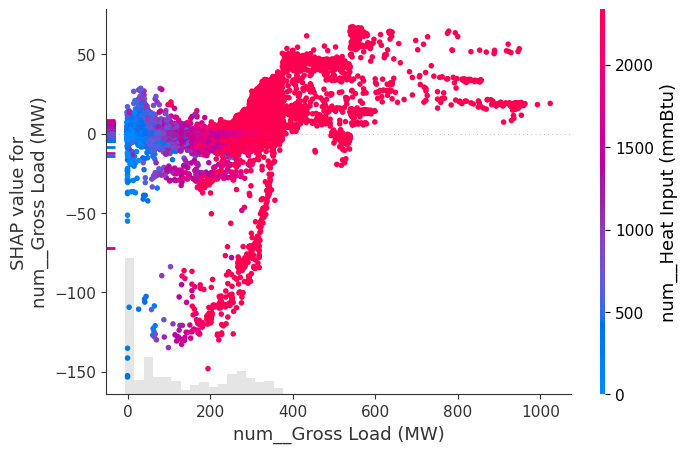

In [9]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


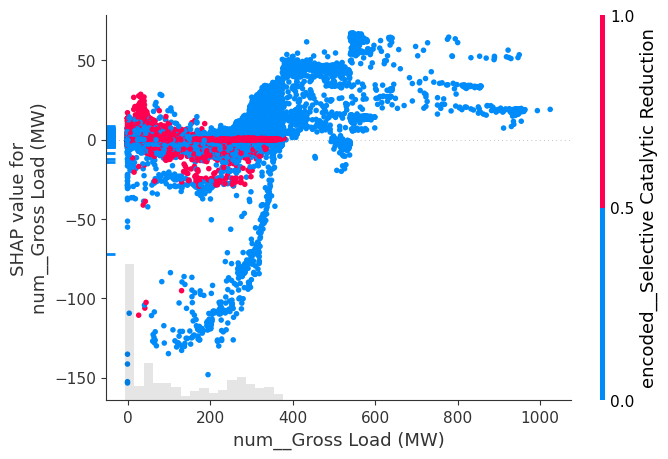

In [10]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])


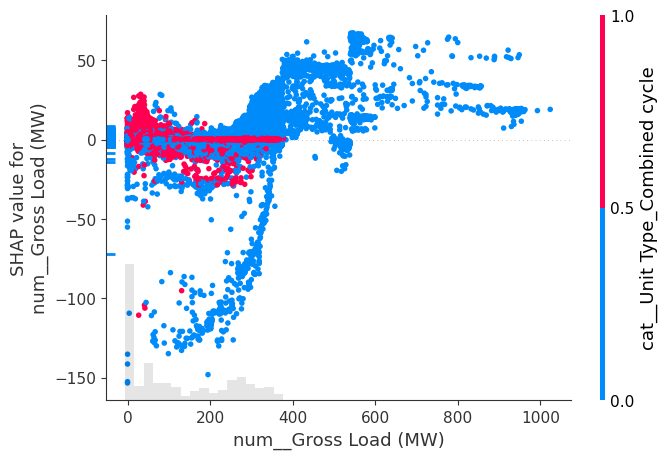

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"cat__Unit Type_Combined cycle"])  


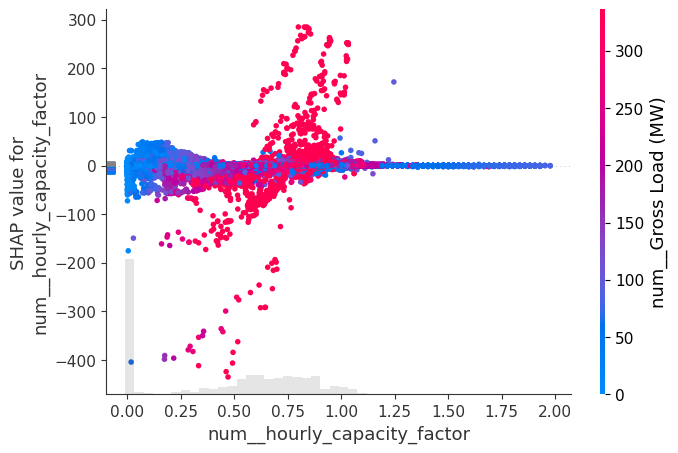

In [12]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"], color=shap_values[:,"num__Gross Load (MW)"])


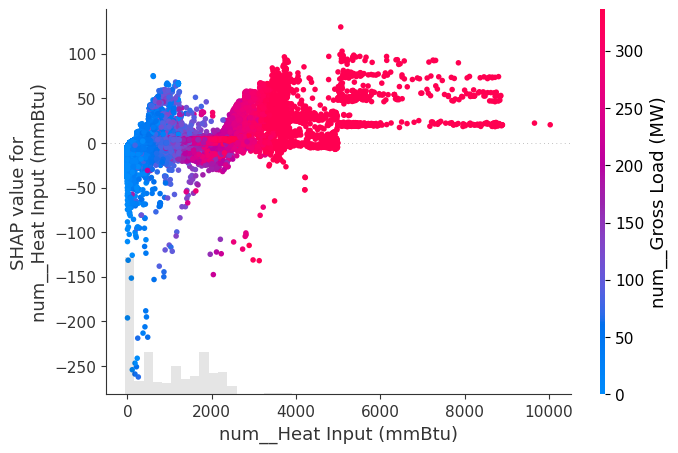

In [13]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


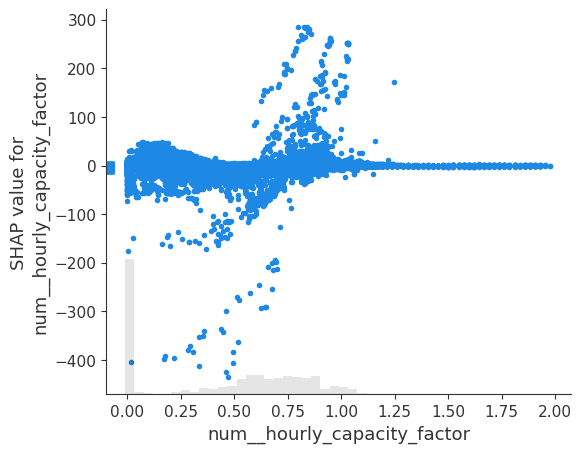

In [14]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"])#, color=shap_values[:,"encoded__Selective Catalytic Reduction"])


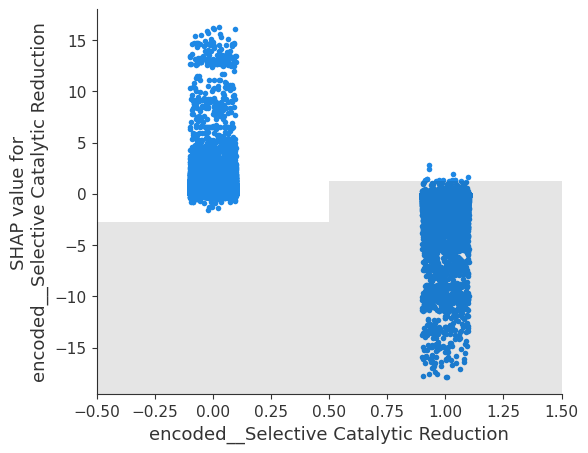

In [15]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"])


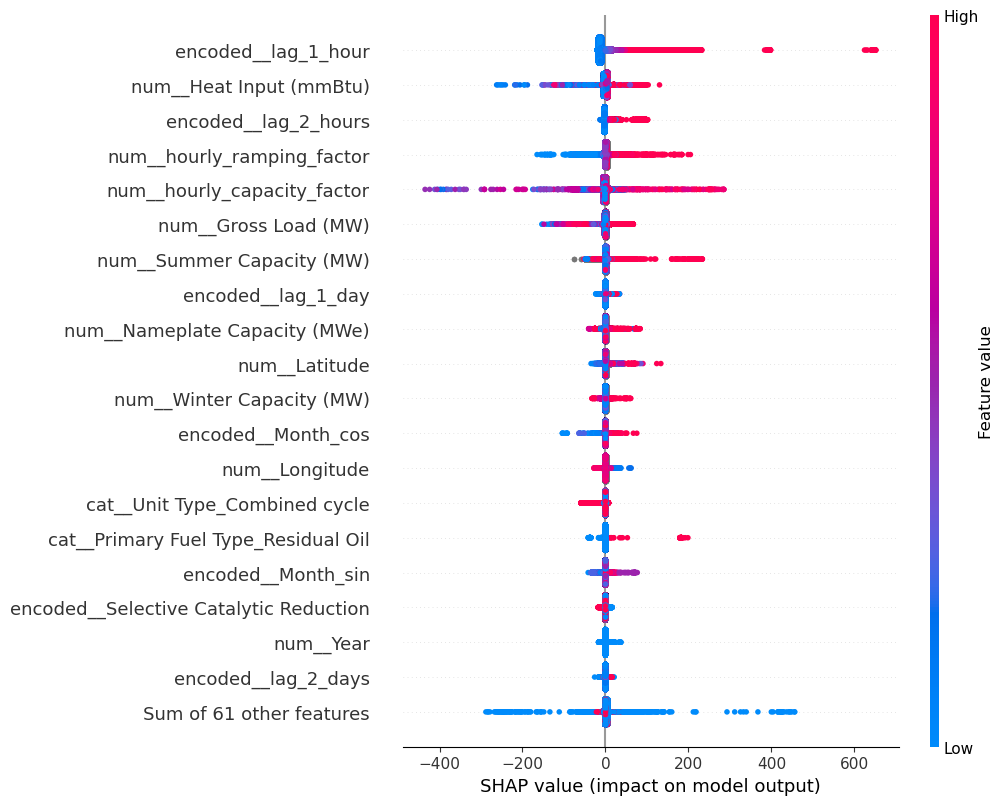

In [16]:
shap.plots.beeswarm(shap_values, max_display=20)


In [17]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

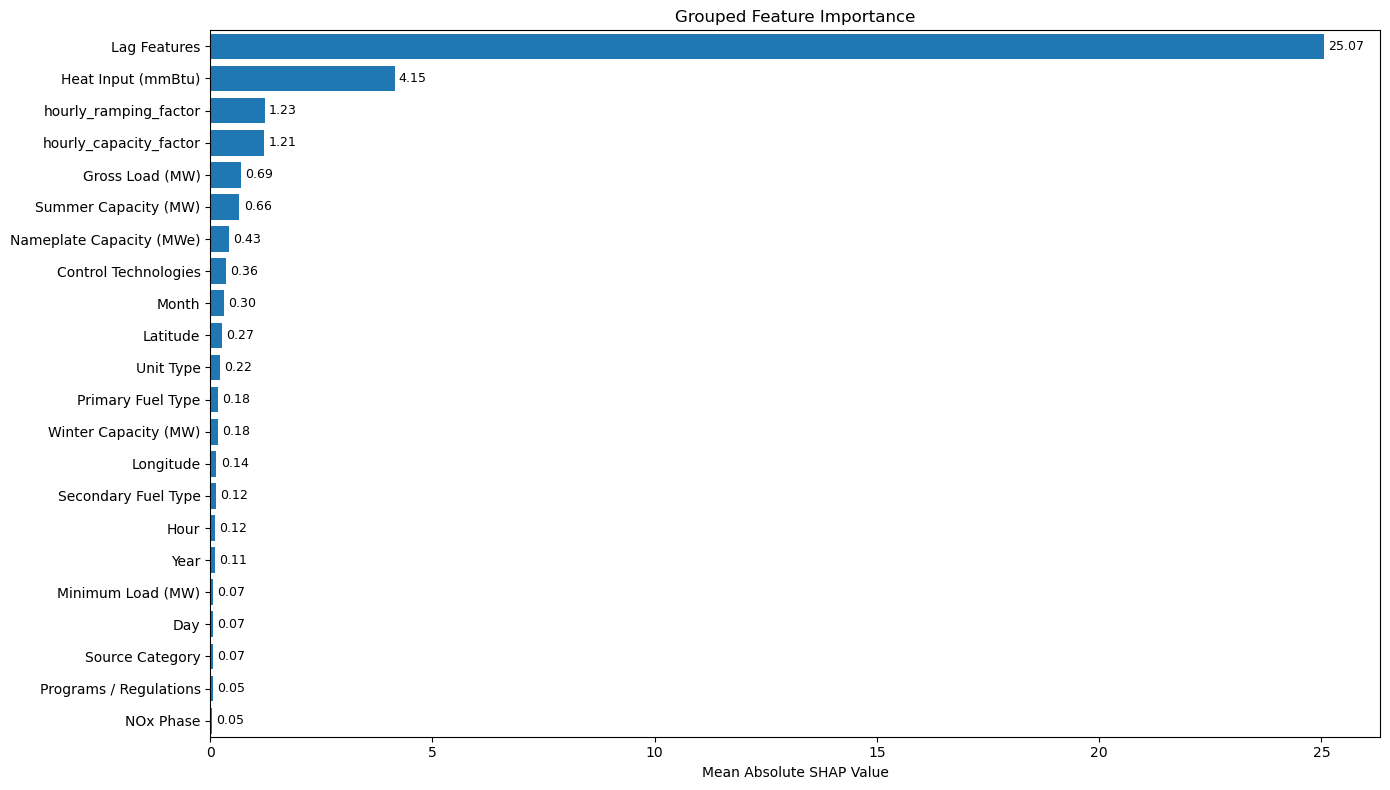

In [18]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()
